# Import and Functions

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import math
import sys
import ast
import os
import matplotlib.patheffects as path_effects
sys.path.append('../')
from utils.Evaluation.calculate_metrics import calculate_scores
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as path_effects
sns.set_style(style='whitegrid')  # Better background
from collections import defaultdict, Counter
from typing import List, Tuple, Dict
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import sem
from matplotlib.cm import get_cmap
import colorsys
import numpy as np
import matplotlib.pyplot as plt

In [2]:
error_categories_with_errors={
    'Schema Errors':[
    'Neo.ClientNotification.Statement.UnknownLabelWarning',
    'Neo.ClientNotification.Statement.UnknownRelationshipTypeWarning',
    'UnknownPathWarning',
    'WrongDirectionPathWarning',
    'VariableLengthPathWarning',
    'WrongDirectionPath&VariableLengthPathWarning'
],
 'Properties Errors':[
    'Neo.ClientNotification.Statement.UnknownPropertyKeyWarning',
    'InvalidPropertyAccessByLabelWarning'
],
'Syntax Errors':['Neo.ClientError.Statement.SyntaxError',
'Neo.DatabaseError.Statement.ExecutionFailed',
'Neo.ClientError.Statement.SyntaxError',
'Neo.ClientNotification.Statement.ParameterNotProvided',
'Neo.ClientNotification.Statement.UnsatisfiableRelationshipTypeExpression',
'Neo.ClientError.Statement.ArithmeticError',
'ConflictingVariablesError',
'Neo.ClientError.Procedure.ProcedureNotFound']
}

error_to_cat = {err: cat for cat, errs in error_categories_with_errors.items() for err in errs}

In [3]:
def extract_dfs(df):

    kg_valid_queries_df = df[df['is_KG_Valid_correct']==True].reset_index(drop=True)
    unavailable_output_df = df[df['answer']=="I couldn't find any relevant information in the database"].reset_index(drop=True)
    kg_valid_queries_with_full_schema_df = df[df['is_KG_Valid_correct_with_full_schema']==True].reset_index(drop=True)
    kg_valid_queries_with_filtered_schema_df = df[(df['is_KG_Valid_correct_with_full_schema']==False) & (df['is_KG_Valid_correct']==True)].reset_index(drop=True)

    return kg_valid_queries_df,unavailable_output_df,kg_valid_queries_with_full_schema_df,kg_valid_queries_with_filtered_schema_df

def extract_params(model_name):
    import re
    match = re.search(r'([\d.]+)[bB]', model_name)
    if match:
        return float(match.group(1))
    return 1000  # Default if no match

def count_tries(row):
    path = row['path']
    cypher_corrector_freq = path.count('cypher_corrector')
    if 'schema_retriever' in path:
        # KG valid with full schema
        if 'output_generator' in path:
            count = cypher_corrector_freq - 5
        # Unvailable Output
        else:
            count = None
    # KG Valid with filtered schema
    else:
        count = cypher_corrector_freq
    return count

def remove_duplicates(row):
    unique_elements =row[:len(row) // 2]
    return unique_elements

def extract_error_types_as_lists(nested_list):
    return [[s.split(':')[0].strip() for s in sublist] for sublist in nested_list]

def extract_error_types(nested_list):
    return [s.split(':')[0] for sublist in nested_list for s in sublist]

# Function to transform list of lists to list of lists of (category, error) tuples
def map_errors_codes_to_categories(nested_error_list):
    if not nested_error_list:
        return [[('No errors', None)]]
    result = []
    for inner_list in nested_error_list:
        if not inner_list:
            result.append([('No errors', None)])
        else:
            result.append([(error_to_cat.get(err, 'Unknown'), err) for err in inner_list])
    return result

def map_errors_to_categories(nested_error_list):
    if not nested_error_list:
        return [[('No errors', None)]]
    result = []
    for inner_list in nested_error_list:
        if not inner_list:
            result.append([('No errors', None)])
        else:
            result.append([(error_to_cat.get(err.split(':')[0].strip(), 'Unknown'), err) for err in inner_list])
    return result

def calculate_dicts(source_directory,extended=True):
    dict_with_models={}
    for name in os.listdir(source_directory):
        folder_path = os.path.join(source_directory, name)
        if os.path.isdir(folder_path):
            # “name” is an immediate folder
            print(f"Entering folder: {folder_path}")
            # do your work here, e.g. list files inside:
            for file in os.listdir(folder_path):
                file_path = os.path.join(folder_path, file)
                if file.endswith('.xlsx'):
                    df_all = pd.read_excel(file_path)
                    
                    if 'Sustain' in file_path:
                        df = df_all
                    else:
                        df = df_all[df_all['Original_KG_Valid']==True].reset_index(drop=True)
                    
                    if extended:
                        list_columns = ['path','cypher_errors_history', 'cypher_errors']
                        for col in list_columns:
                            df[col] = df[col].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
                        
                        # Extract error types from cypher_errors_history
                        df['cypher_errors_history'] = df['cypher_errors_history'].apply(remove_duplicates)
                        df['flattened_cypher_errors_history'] = df['cypher_errors_history'].apply(extract_error_types)
                        df['cypher_errors_codes_history'] = df['cypher_errors_history'].apply(extract_error_types_as_lists)
                        df['cypher_errors_codes_with_categories'] = df['cypher_errors_codes_history'].apply(map_errors_codes_to_categories)
                        df['cypher_errors_with_categories'] = df['cypher_errors_history'].apply(map_errors_to_categories)
                        
                    model_name = file.split('.')[0]
                    model_name = model_name.replace('openrouter_', '')
                    model_name = model_name.replace('_local', '')
                    dict_with_models[model_name] = df        

    return dict_with_models

# Create a dict with the results for each key(model_name)

Activate the dataset to test

In [4]:
# BenchmarkDataset
models_mapping = {
    'gpt_4o':'gpt4o', 
    'llama3_2_3b':'Llama-3.2-3B-Instruct',
    'finetuned_azzedde_llama3_1_8b':'Finetuned-AzzedeLlama-3.1-8b',
    'llama3_1_8b':'Llama-3.1-8B-Instruct',
    'gemma2_9b':'gemma-2-9b-it',
    'finetuned_gemma2_9b': 'Finetuned-gemma-2-9b-it'
}

dataset = 'BenchmarkDataset2025'

# SustainDataset
# models_mapping = {
#     'gpt_4o':'gpt4o', 
#     'llama3_2_3b':'Llama-3.2-3B-Instruct',
#     'qwen2_5_72b':'Qwen2.5-72B-Instruct',
#     'qwen2_5_7b':'Qwen2.5-7B-Instruct',
#     'qwen2_5_Coder_32b':'Qwen2.5-Coder-32B-Instruct'
# }

# dataset = 'SustainDataset'

In [5]:
extended_dfs_dict = calculate_dicts("./extended_workflow/Outputs_Evaluation/"+dataset,extended=True)
extended_dfs_dict = dict(sorted(extended_dfs_dict.items(), key=lambda item: extract_params(item[0])))

Entering folder: ./extended_workflow/Outputs_Evaluation/BenchmarkDataset2025\finetuned_azzedde_llama3_1_8b
Entering folder: ./extended_workflow/Outputs_Evaluation/BenchmarkDataset2025\finetuned_gemma2_9b_local
Entering folder: ./extended_workflow/Outputs_Evaluation/BenchmarkDataset2025\gemma2_9b
Entering folder: ./extended_workflow/Outputs_Evaluation/BenchmarkDataset2025\gpt_4o
Entering folder: ./extended_workflow/Outputs_Evaluation/BenchmarkDataset2025\llama3_1_8b
Entering folder: ./extended_workflow/Outputs_Evaluation/BenchmarkDataset2025\llama3_2_3b


# 📖 Paper plots

## Evaluation of LLM Outputs Errors

### 🧮 Error Change Analysis: Iteration-by-Iteration Tracking

This analysis tracks how Cypher error types evolve across each iteration of the correction workflow.  
For every error category (**Syntax Errors**, **Schema Errors**, **Properties Errors**), we compute:

- **Persistent Errors**:  
    The number of error instances that remain from the previous iteration to the current one.

- **New Errors**:  
    The number of error instances that appear for the first time in the current iteration.

- **Disappeared Errors**:  
    The number of error instances that were present in the previous iteration but are now resolved.

- **Delta Count**:  
    The net change in error instances for each category (`New - Disappeared`).

**How it works:**  
For each iteration, we compare the error codes in the current snapshot to those in the previous one:
- *Persistent*: For each error code, count the minimum number of times it appears in both iterations.
- *New*: For each error code, count how many more times it appears now than before (if any).
- *Disappeared*: For each error code, count how many fewer times it appears now than before (if any).
- *Delta*: The difference between new and disappeared counts.

This breakdown helps visualize which errors are being fixed, which persist, and which are newly introduced as the correction process progresses.

---

In [6]:
def analyze_error_changes(error_snapshots: List[List[Tuple[str, str]]]) -> pd.DataFrame:
    """
    Track error changes over iterations for a fixed set of categories.

    Parameters
    ----------
    error_snapshots : List of iterations. Each is a list of (category, error_code) tuples.
                      Example: [[('Syntax Errors', 'E1'), ...], [('No errors', None)], ...]

    Returns
    -------
    pd.DataFrame : A record of how many errors per category disappeared, persisted, or are new,
                   for each iteration.
    """
    all_categories = ['Syntax Errors', 'Schema Errors', 'Properties Errors']  # fixed categories
    # all_categories = list({
    #     category
    #     for run in error_snapshots
    #     for category, _ in run
    #     if category != 'No errors'
    # })
    records = []

    for i, snapshot in enumerate(error_snapshots):
        if i==6 or i==0:
            prev = {}
            # print('Start of iteration:', i)
            # print(snapshot)
        # If snapshot is just [('No errors', None)], treat it as empty
        only_no_errors = (len(snapshot) == 1 and snapshot[0][0] == 'No errors')

        # Build current iteration’s error counter: category → Counter(error_code → count)
        curr = defaultdict(Counter)
        if not only_no_errors:
            for cat, err in snapshot:
                if cat != 'No errors':
                    curr[cat][err] += 1

        # Compare each known category between prev and curr
        for cat in all_categories:
            p, c = prev.get(cat, Counter()), curr.get(cat, Counter())
            # print(cat)
            # print(p,c)

            # Persisted: overlapping errors (min count)
            # Iterates over all erros seen in the previous iteration, 
            # For each error in prev, it checks how many times it appears in curr and take the minimum
            # Sum up to get the total persisted count
            persistent = sum(min(p[e], c[e]) for e in p)
            # for e in c:
            #     print(e,p[e],c[e])
                # print(e,min(p[e], c[e]))
            # New:
            # Iterates over all erros seen in the previous iteration, 
            # p.get(e, 0) is how many times it appeared before (0 if it never did).
            # max(...) ensures we only count positive gains as new.
            # Sum up to get the newly introduced error count
            new = sum(max(c[e] - p.get(e, 0), 0) for e in c)

            disappeared = sum(max(p[e] - c.get(e, 0), 0) for e in p)

            # Net change: DeltaCount = NewCount - DisappearedCount
            delta = new - disappeared 


            # Record results
            records.append({
                'Iteration': i,
                'Category': cat,
                'PersistentCount': persistent if not only_no_errors else 0,
                'DisappearedCount': disappeared ,
                'NewCount': new if not only_no_errors else 0,
                'DeltaCount': delta ,  # This can be negative or positive
            })
        # print('End of iteration:', i)
        # print()

        prev = curr  # update for next iteration

    return pd.DataFrame(records)

In [7]:
error_dfs = []
for model_name, df in extended_dfs_dict.items():
    list_of_dfs = []
    for i, row in df.iterrows():
        run_df = analyze_error_changes(row['cypher_errors_with_categories'])
        run_df['Group'] = np.where(
        (row['is_KG_Valid_correct_with_full_schema'] == False) & (row['is_KG_Valid_correct'] == True),
        'KG Valid Queries (Filtered Schema)',
        np.where(row['is_KG_Valid_correct_with_full_schema'] == True,'KG Valid Queries (Full Schema)' , 'Unavailable Output')
        )
        run_df['RunID'] = i
        list_of_dfs.append(run_df)

    df_over_iter = pd.concat(list_of_dfs, ignore_index=True)
    df_over_iter['Model'] = models_mapping[model_name]
    error_dfs.append(df_over_iter)

errors_df_before = pd.concat(error_dfs, ignore_index=True) 

# Step 1: Get max iteration per RunID
max_iterations = errors_df_before.groupby('RunID')['Iteration'].max().reset_index()
max_iterations['Phase'] = max_iterations['Iteration'].apply(lambda x: 'Filtered Schema' if x <= 5 else 'Full Schema')

# # Step 2: Merge back to original DataFrame
errors_df = errors_df_before.merge(max_iterations[['RunID', 'Phase']], on='RunID', how='left')

C:\Users\ioann\AppData\Local\Temp\ipykernel_31972\1526048725.py:70: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  annotate_axis(ax_new, max_x, y_center=max_values[1])
C:\Users\ioann\AppData\Local\Temp\ipykernel_31972\1526048725.py:70: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  annotate_axis(ax_new, max_x, y_center=max_values[1])
C:\Users\ioann\AppData\Local\Temp\ipykernel_31972\1526048725.py:70: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.i

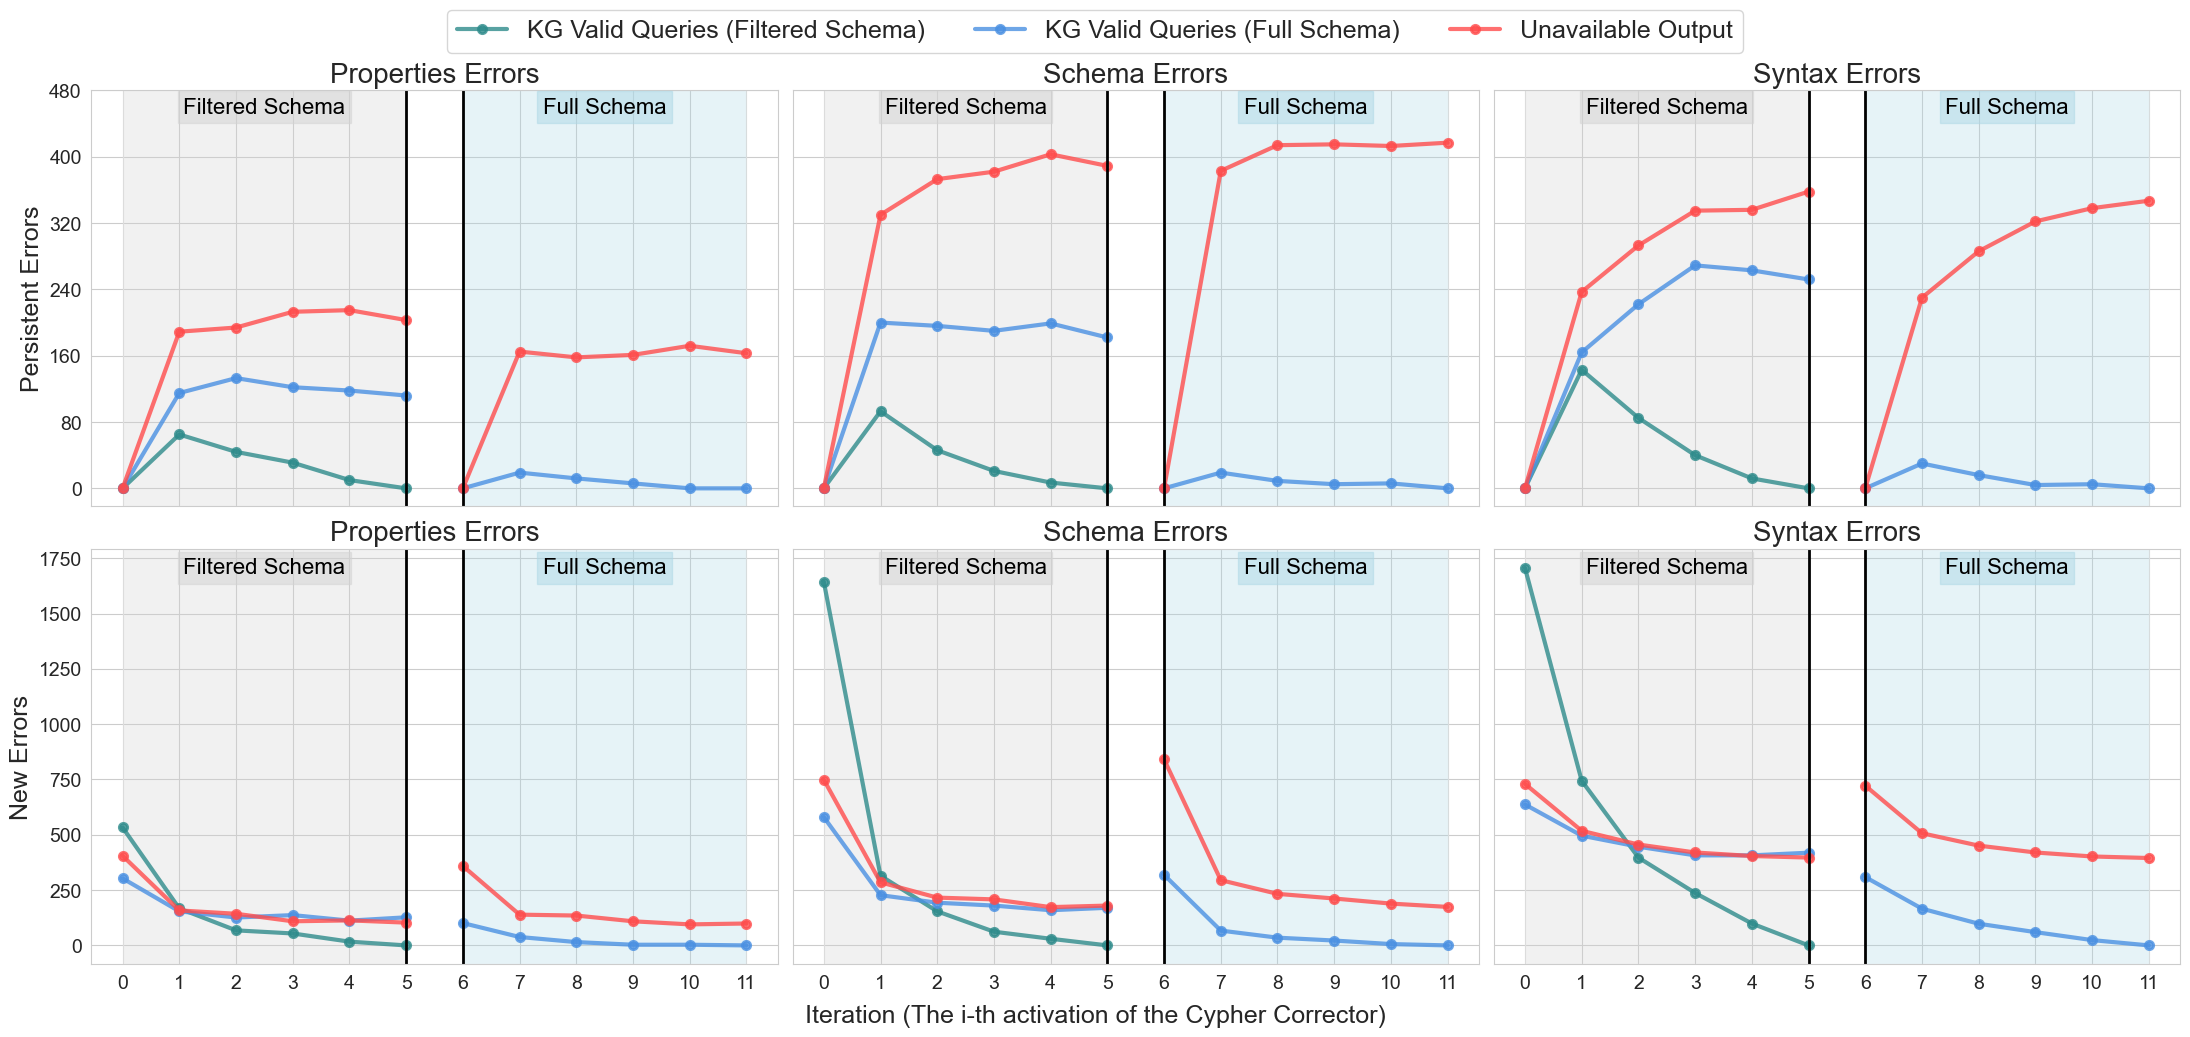

In [8]:
# Group by Iteration, Group, and Category
agg_flux = errors_df.groupby(['Iteration', 'Group', 'Category'])[['PersistentCount', 'NewCount']].sum().reset_index()
max_values = agg_flux.groupby(['Group'])[['PersistentCount', 'NewCount']].max().max()

# Get unique categories
categories = sorted(agg_flux['Category'].unique())

base_colors = ['#2E8B8B', '#4A90E2', '#FF4C4C']

# Create 2x3 subplot grid
fig, axes = plt.subplots(2, 3, figsize=(22, 10), sharex=True, sharey='row')

# Annotation helper function
def annotate_axis(ax, max_x, y_center):
    ax.axvline(x=5, color='black', linestyle='-', linewidth=2)
    ax.axvline(x=6, color='black', linestyle='-', linewidth=2)
    ax.axvspan(0, 5, ymin=0, ymax=1, facecolor='lightgray', alpha=0.3)
    ax.axvspan(6, max_x, ymin=0, ymax=1, facecolor='lightblue', alpha=0.3)
    
    ax.text(2.5, y_center, 'Filtered Schema', fontsize=16, color='black',
            ha='center', va='center', bbox=dict(facecolor='lightgray', alpha=0.5, edgecolor='lightgray'))

    ax.text(8.5, y_center, 'Full Schema', fontsize=16, color='black',
            ha='center', va='center', bbox=dict(facecolor='lightblue', alpha=0.5, edgecolor='lightblue'))

# Loop through categories and plot
for i, category in enumerate(categories):

        cat_data = agg_flux[agg_flux['Category'] == category]
        # cat_data.Iteration = cat_data.Iteration + 1

        # Pivot for plotting
        persisted_pivot = cat_data.pivot(index='Iteration', columns='Group', values='PersistentCount')
        new_pivot = cat_data.pivot(index='Iteration', columns='Group', values='NewCount')

        # Insert NaNs to break the line between iteration 5 and 6
        persisted_pivot.loc[5.5] = np.nan
        new_pivot.loc[5.5] = np.nan
        persisted_pivot = persisted_pivot.sort_index()
        new_pivot = new_pivot.sort_index()

        # Plot Persisted
        ax_persisted = axes[0, i]
        persisted_pivot.plot(ax=ax_persisted, marker='o', alpha=0.8, legend=False,color=base_colors,linewidth=3,markeredgewidth=2)
        ax_persisted.set_title(category,size=20)
        ax_persisted.set_ylabel("Persistent Errors",size=18)
        ax_persisted.set_xlabel("Iteration")
        ax_persisted.set_xticks(np.arange(persisted_pivot.index.min(), persisted_pivot.index.max() + 1, 1))
        ax_persisted.set_yticks(np.arange(0, 500,80))
        ax_persisted.tick_params(axis='y', labelsize=14)  # Change 14 to your desired font size


        max_x = persisted_pivot.index.max()
        annotate_axis(ax_persisted, max_x, y_center=460)

        # Plot New
        ax_new = axes[1, i]
        new_pivot.plot(ax=ax_new, marker='o', alpha=0.8, legend=False,color=base_colors,linewidth=3,markeredgewidth=2)
        ax_new.set_title(category,size=20)
        ax_new.set_ylabel("New Errors",size=18)
        ax_new.set_xlabel("",size=18)
        ax_new.set_xticks(np.arange(new_pivot.index.min(), new_pivot.index.max() + 1, 1))
        ax_new.tick_params(axis='x', labelsize=14)  # Change 14 to your desired font size
        ax_new.tick_params(axis='x', labelsize=14)  # Change 14 to your desired font size
        ax_new.tick_params(axis='y', labelsize=14)  # Change 14 to your desired font size



        max_x = new_pivot.index.max()
        annotate_axis(ax_new, max_x, y_center=max_values[1])

# Tight layout below legend space
fig.tight_layout(rect=[0, 0, 1, 0.96])

# Shared legend (using first plot’s handles)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.supxlabel("Iteration (The i-th activation of the Cypher Corrector)",size=18,y=-0.02)
fig.legend(handles, labels, title='', loc='upper center', ncol=len(labels), bbox_to_anchor=(0.5, 1.01),fontsize=18)
# plt.savefig('Figures/error_Analysis.jpg', dpi=300, bbox_inches='tight')
plt.show()

## Ablation Study on the number of iterations and full schema fallback mechanism

### 🔄 Error Correction Dynamics: Persistent vs. New Errors Over Iterations

The plots below illustrate how Cypher error types change throughout the iterative correction workflow for each model and error category:

- **Top Row:** Shows the number of **persistent errors** (errors that remain from the previous iteration) for each error category and query group, across iterations.
- **Bottom Row:** Shows the number of **new errors** (errors introduced in the current iteration) for each error category and query group, across iterations.

**Key Features:**
- The workflow is divided into two phases:  
    - **Filtered Schema** (Iterations 0–5, shaded gray)  
    - **Full Schema** (Iterations 6+, shaded blue)
- Each colored line represents a different query group:
    - *KG Valid Queries (Filtered Schema)*
    - *KG Valid Queries (Full Schema)*
    - *Unavailable Output*
- Vertical lines mark the transition between phases.

**Interpretation:**  
These plots help visualize the effectiveness of error correction at each step, showing which errors persist, which are resolved, and which new errors are introduced as the workflow progresses.

In [7]:
all_dfs =[]
for model_name, df in extended_dfs_dict.items():
    # Iteration and Group
    df['Iteration'] = df.apply(count_tries, axis=1)
    df['Group'] = np.where(
    (df['is_KG_Valid_correct_with_full_schema'] == False) & (df['is_KG_Valid_correct'] == True),
    'KG Valid Queries (Filtered Schema)',
    np.where(df['is_KG_Valid_correct_with_full_schema'] == True,'KG Valid Queries (Full Schema)' , 'Unavailable Output')
    )
    # GroupBy
    grouped_df = df.groupby(['Group','Iteration'], dropna=False).size().reset_index(name='Value')
    grouped_df['Model'] = models_mapping[model_name]
    all_dfs.append(grouped_df)

all_df = pd.concat(all_dfs, ignore_index=True)


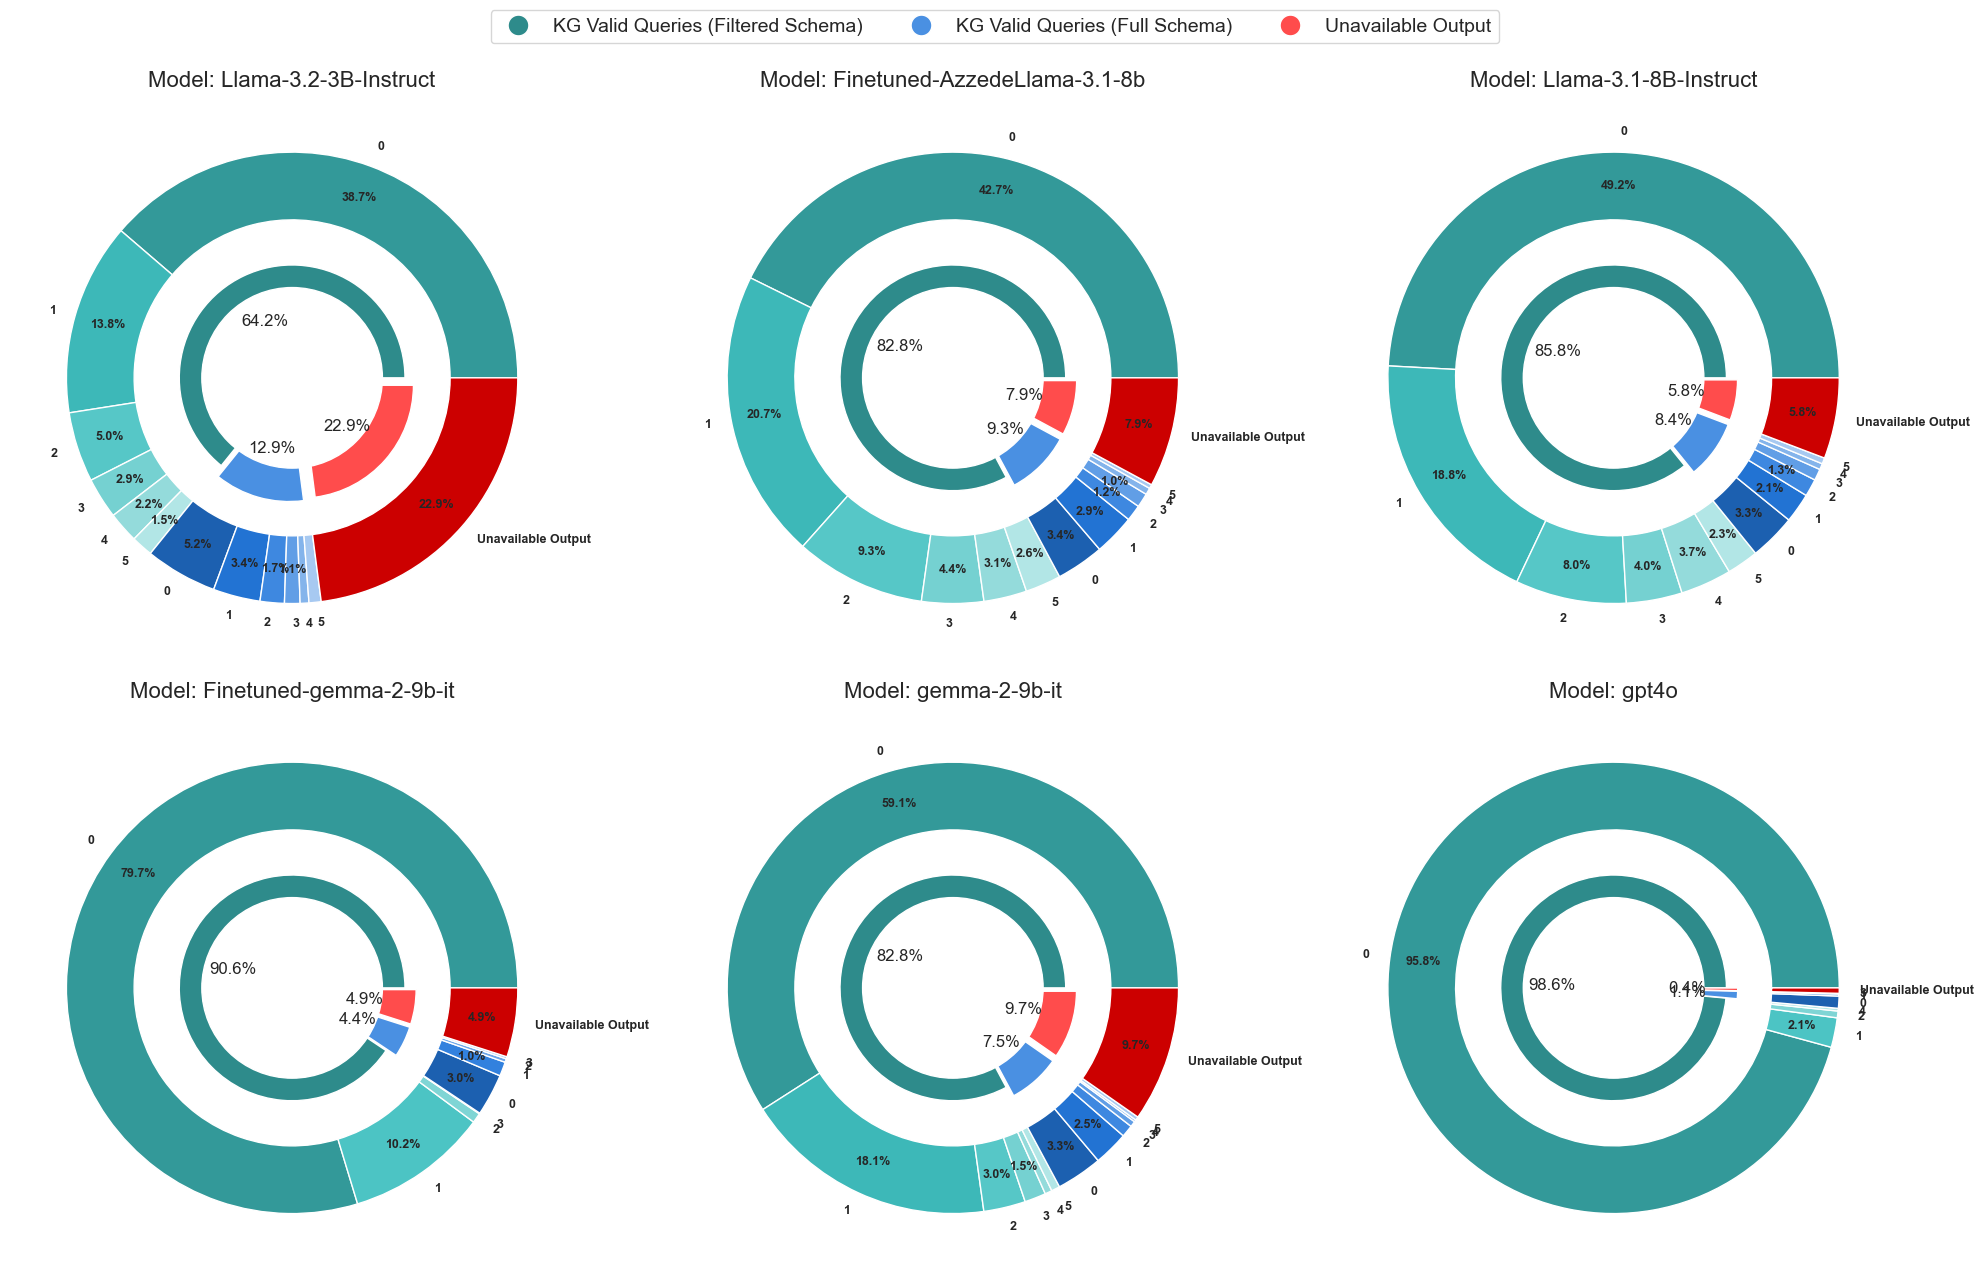

In [10]:
all_df_copy = all_df.copy()
all_df_copy['Iteration'] = all_df_copy['Iteration'].fillna('Unavailable Output')
all_df_copy['Iteration'] = all_df_copy['Iteration'].astype(str)
models = all_df_copy['Model'].unique()
num_models = len(models)

ncols = 3
nrows = int(np.ceil(num_models / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(20, 13), subplot_kw=dict(aspect="equal"))
axs = axs.flatten() if num_models > 1 else [axs]

base_colors = ['#2E8B8B', '#4A90E2', '#FF4C4C']

def hex_to_rgb_fraction(hex_color):
    hex_color = hex_color.lstrip('#')
    return tuple(int(hex_color[i:i+2], 16)/255 for i in (0, 2, 4))

def autopct_format(pct):
    return f'{pct:.01f}%' if pct > 1 else ''

def clean_iteration_label(x):
    try:
        return str(int(float(x))) #+ ' Iter.'  # Convert numeric-looking strings like "2.0" → "2"
    except:
        return x  # Keep non-numeric ones like "Unavailable Output"



for ax, model in zip(axs, models):
    df = all_df_copy[all_df_copy['Model'] == model]
    group_totals = df.groupby('Group')['Value'].sum()
    group_labels = group_totals.index
    group_sizes = group_totals.values

    group_color_map = {g: base_colors[i % len(base_colors)] for i, g in enumerate(group_labels)}

    # Generate iteration colors as shades of group color
    iteration_colors = []
    for _, row in df.iterrows():
        base_rgb = hex_to_rgb_fraction(group_color_map[row['Group']])
        h, l, s = colorsys.rgb_to_hls(*base_rgb)
        group_iters = df[df['Group'] == row['Group']]['Iteration'].unique()
        iter_idx = np.where(group_iters == row['Iteration'])[0][0]
        lightness = 0.4 + 0.4 * (iter_idx / max(len(group_iters) - 1, 1))
        rgb = colorsys.hls_to_rgb(h, lightness, s)
        iteration_colors.append(rgb)

   # Outer pie explode: add gap **only before** slices where group changes (except very first slice)
    gap_size_outer = 0.05
    explode_outer = []
    prev_group = None
    for i, (_, row) in enumerate(df.iterrows()):
        if i == 0:
            explode_outer.append(0)  # no gap for first slice
        else:
            explode_outer.append(gap_size_outer if row['Group'] != prev_group else 0)
        prev_group = row['Group']

    # Inner pie explode: 0 for first group slice, gap for all others to separate groups
    gap_size_inner = 0.05
    explode_inner = [0] + [gap_size_inner] * (len(group_labels) - 1)


    # Outer pie (Iterations)
    wedges_outer, _, autotexts_outer = ax.pie(
        df['Value'],
        radius=1,
        labels = df['Iteration'].apply(clean_iteration_label),
        labeldistance=1.09,#None
        colors=iteration_colors,
        wedgeprops=dict(width=0.3, edgecolor='white'),
        autopct=autopct_format,
        pctdistance=0.85,
        textprops=dict(size=9, weight='bold'),
        # explode=explode_outer  # uncomment if explode desired
    )
    ## apply labels to wedges
    # labels = df['Iteration'].apply(clean_iteration_label)
    # for wedge, label in zip(wedges_outer, labels):
    #     angle = (wedge.theta2 + wedge.theta1) / 2.0
    #     x = math.cos(math.radians(angle))
    #     y = math.sin(math.radians(angle))

    #     ha = "left" if x >= 0 else "right"
    #     ax.text(x * 1.05, y * 1.05, label,
    #             horizontalalignment=ha,
    #             verticalalignment='center',
    #             rotation=angle if x >= 0 else angle + 180,
    #             rotation_mode='anchor',
    #             fontsize=9, weight='bold')
        
    # Inner pie (Groups)
    wedges_inner, _, autotexts_inner = ax.pie(
        group_sizes,
        radius=0.5,
        colors=[group_color_map[g] for g in group_labels],
        wedgeprops=dict(width=0.3, edgecolor='white'),
        autopct='%1.1f%%',
        pctdistance=0.55,
        textprops=dict(size=12,),# weight='bold'
        explode=explode_inner,
        #  shadow={'ox': -0.04, 'edgecolor': 'none', 'shade': 0.9}
    )
    
    # Donut center
    ax.add_artist(plt.Circle((0, 0), 0.4, fc='white'))
    ax.set_title(f'Model: {model}', fontsize=16)

# Disable unused axes
for ax in axs[num_models:]:
    ax.axis('off')

# Legend for groups (using last model's group_color_map)
handles = [plt.Line2D([0], [0], marker='o', color='w', label=group,
                      markerfacecolor=color, markersize=15)
           for group, color in group_color_map.items()]

fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 1), ncol=len(group_color_map), fontsize=14)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

## For the publication

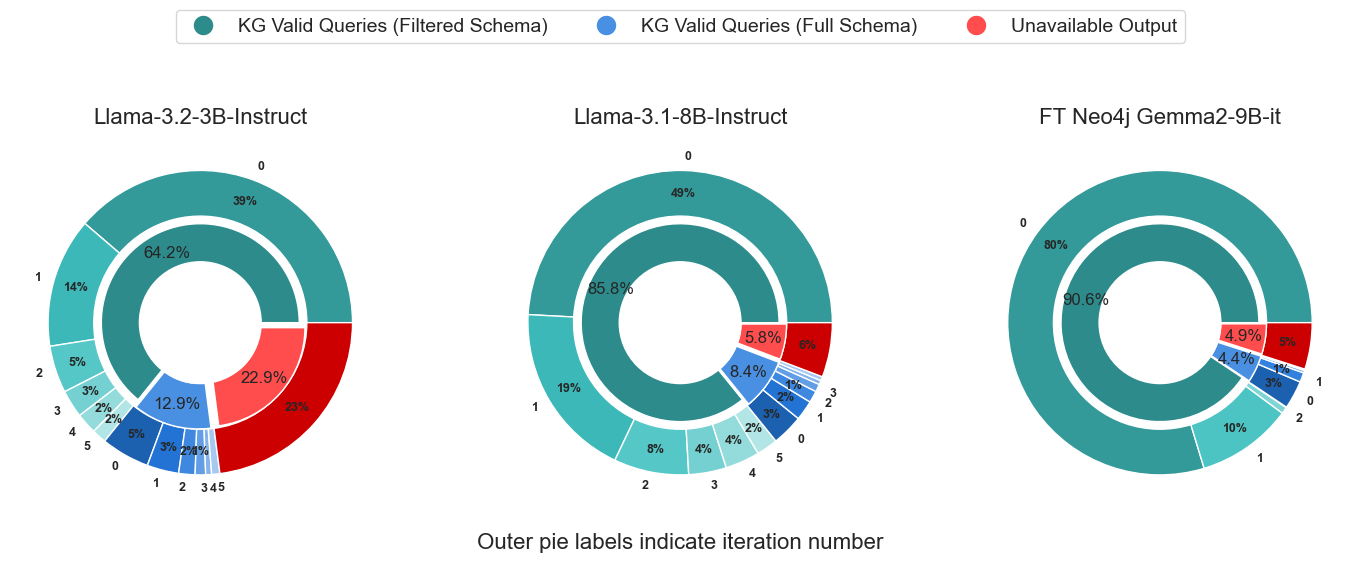

In [30]:
all_df_copy = all_df.copy()
all_df_copy = all_df_copy[all_df_copy['Model'].isin(['Llama-3.2-3B-Instruct','Llama-3.1-8B-Instruct','Finetuned-gemma-2-9b-it'])]
all_df_copy['Iteration'] = all_df_copy['Iteration'].fillna('Unavailable Output')
all_df_copy['Iteration'] = all_df_copy['Iteration'].astype(str)
models = all_df_copy['Model'].unique()
num_models = len(models)

ncols = 3
nrows = int(np.ceil(num_models / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(16,5), subplot_kw=dict(aspect="equal"))
fig.subplots_adjust(
    left=0.02, right=0.98,
    top=0.82, bottom=0.12,
    wspace=0.05, hspace=0.10
)

axs = axs.flatten() if num_models > 1 else [axs]

base_colors = ['#2E8B8B', '#4A90E2', '#FF4C4C']

def hex_to_rgb_fraction(hex_color):
    hex_color = hex_color.lstrip('#')
    return tuple(int(hex_color[i:i+2], 16)/255 for i in (0, 2, 4))

def autopct_format(pct):
    return f'{pct:.0f}%' if pct > 1 else ''

def clean_iteration_label(x):
    try:
        return str(int(float(x))) #+ ' Iter.'  # Convert numeric-looking strings like "2.0" → "2"
    except:
        return ''#x  # Keep non-numeric ones like "Unavailable Output"



for ax, model in zip(axs, models):
    df = all_df_copy[all_df_copy['Model'] == model]
    group_totals = df.groupby('Group')['Value'].sum()
    group_labels = group_totals.index
    group_sizes = group_totals.values

    group_color_map = {g: base_colors[i % len(base_colors)] for i, g in enumerate(group_labels)}

    # Generate iteration colors as shades of group color
    iteration_colors = []
    for _, row in df.iterrows():
        base_rgb = hex_to_rgb_fraction(group_color_map[row['Group']])
        h, l, s = colorsys.rgb_to_hls(*base_rgb)
        group_iters = df[df['Group'] == row['Group']]['Iteration'].unique()
        iter_idx = np.where(group_iters == row['Iteration'])[0][0]
        lightness = 0.4 + 0.4 * (iter_idx / max(len(group_iters) - 1, 1))
        rgb = colorsys.hls_to_rgb(h, lightness, s)
        iteration_colors.append(rgb)

   # Outer pie explode: add gap **only before** slices where group changes (except very first slice)
    gap_size_outer = 0.05
    explode_outer = []
    prev_group = None
    for i, (_, row) in enumerate(df.iterrows()):
        if i == 0:
            explode_outer.append(0)  # no gap for first slice
        else:
            explode_outer.append(gap_size_outer if row['Group'] != prev_group else 0)
        prev_group = row['Group']

    # Inner pie explode: 0 for first group slice, gap for all others to separate groups
    gap_size_inner = 0.05
    explode_inner = [0] + [gap_size_inner] * (len(group_labels) - 1)

    outer_labels = [
        clean_iteration_label(it) if val >= 10 else ""
        for it, val in zip(df["Iteration"], df["Value"])
    ]
    # Outer pie (Iterations)
    wedges_outer, _, autotexts_outer = ax.pie(
        df['Value'],
        radius=1,
        labels = outer_labels,#df['Iteration'].apply(clean_iteration_label),
        labeldistance=1.09,#None
        colors=iteration_colors,
        wedgeprops=dict(width=0.3, edgecolor='white'),
        autopct=autopct_format,
        pctdistance=0.85,
        textprops=dict(size=9, weight='bold'),
        # explode=explode_outer  # uncomment if explode desired
    )
    ## apply labels to wedges
    # labels = df['Iteration'].apply(clean_iteration_label)
    # for wedge, label in zip(wedges_outer, labels):
    #     angle = (wedge.theta2 + wedge.theta1) / 2.0
    #     x = math.cos(math.radians(angle))
    #     y = math.sin(math.radians(angle))

    #     ha = "left" if x >= 0 else "right"
    #     ax.text(x * 1.05, y * 1.05, label,
    #             horizontalalignment=ha,
    #             verticalalignment='center',
    #             rotation=angle if x >= 0 else angle + 180,
    #             rotation_mode='anchor',
    #             fontsize=9, weight='bold')
        
    # Inner pie (Groups)
    wedges_inner, _, autotexts_inner = ax.pie(
        group_sizes,
        radius=0.65,
        colors=[group_color_map[g] for g in group_labels],
        wedgeprops=dict(width=0.3, edgecolor='white'),
        autopct='%1.1f%%',
        pctdistance=0.78,
        textprops=dict(size=12,),# weight='bold'
        explode=explode_inner,
        #  shadow={'ox': -0.04, 'edgecolor': 'none', 'shade': 0.9}
    )
    
    # Donut center
    ax.add_artist(plt.Circle((0, 0), 0.4, fc='white'))
    if model == 'Finetuned-gemma-2-9b-it':
        ax.set_title(f'FT Neo4j Gemma2-9B-it', fontsize=16)
    else:
        ax.set_title(f'{model}', fontsize=16)

# Disable unused axes
for ax in axs[num_models:]:
    ax.axis('off')

# Legend for groups (using last model's group_color_map)
handles = [plt.Line2D([0], [0], marker='o', color='w', label=group,
                      markerfacecolor=color, markersize=15)
           for group, color in group_color_map.items()]

fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 1), ncol=len(group_color_map), fontsize=14)
# Bottom note
fig.text(0.5, 0.02, "Outer pie labels indicate iteration number", ha="center", va="center", fontsize=16)

plt.tight_layout(rect=[0, 0.05, 1, 0.92])
plt.show()

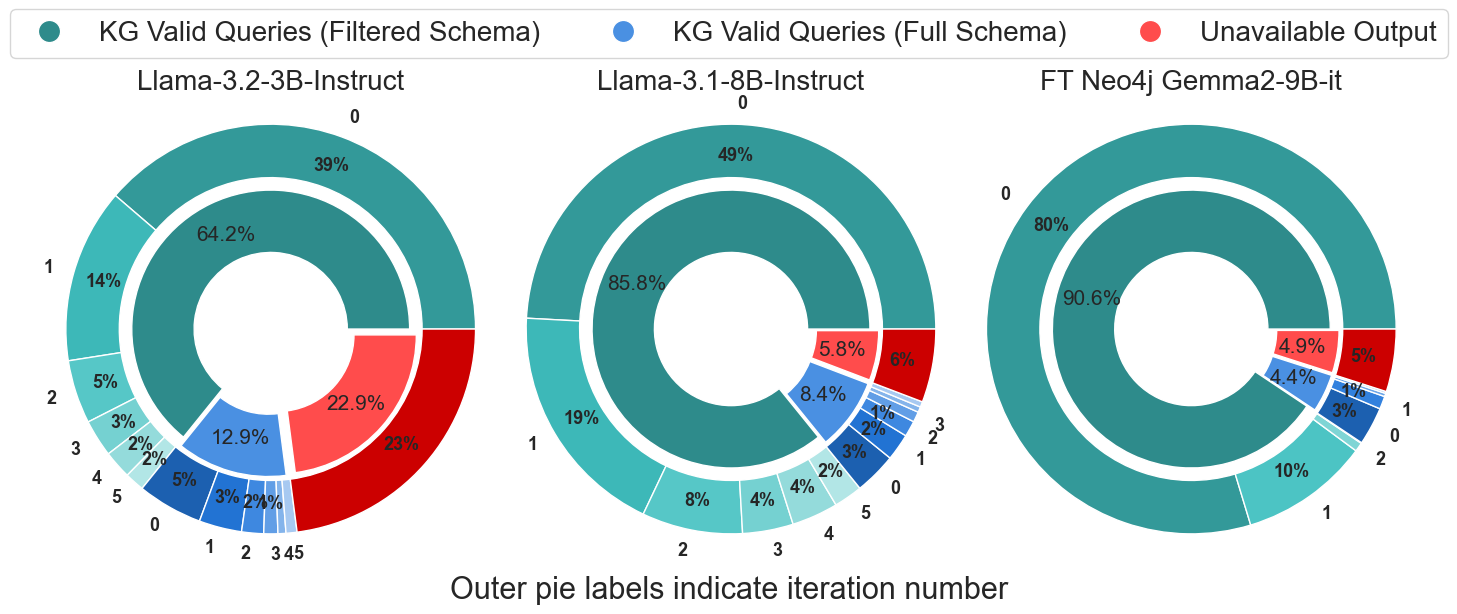

In [20]:
all_df_copy = all_df.copy()
all_df_copy = all_df_copy[
    all_df_copy['Model'].isin([
        'Llama-3.2-3B-Instruct',
        'Llama-3.1-8B-Instruct',
        'Finetuned-gemma-2-9b-it'
    ])
]

all_df_copy['Iteration'] = all_df_copy['Iteration'].fillna('Unavailable Output')
all_df_copy['Iteration'] = all_df_copy['Iteration'].astype(str)

models = all_df_copy['Model'].unique()
num_models = len(models)

# -------------------------
# LAYOUT: bigger pies + tighter spacing
# -------------------------
ncols = 3
nrows = int(np.ceil(num_models / ncols))

fig, axs = plt.subplots(
    nrows, ncols,
    figsize=(14, 6),
    subplot_kw=dict(aspect="equal")
)

fig.subplots_adjust(
    left=0.01, right=0.99,
    top=0.88, bottom=0.10,
    wspace=0.01,
    hspace=0.02
)

axs = axs.flatten() if num_models > 1 else [axs]

base_colors = ['#2E8B8B', '#4A90E2', '#FF4C4C']

def hex_to_rgb_fraction(hex_color):
    hex_color = hex_color.lstrip('#')
    return tuple(int(hex_color[i:i+2], 16)/255 for i in (0, 2, 4))

def autopct_format(pct):
    return f'{pct:.0f}%' if pct > 1 else ''

def clean_iteration_label(x):
    try:
        return str(int(float(x)))
    except:
        return ''

for ax, model in zip(axs, models):
    df = all_df_copy[all_df_copy['Model'] == model]

    group_totals = df.groupby('Group')['Value'].sum()
    group_labels = group_totals.index
    group_sizes = group_totals.values

    group_color_map = {
        g: base_colors[i % len(base_colors)]
        for i, g in enumerate(group_labels)
    }

    # -------------------------
    # Iteration color shading
    # -------------------------
    iteration_colors = []
    for _, row in df.iterrows():
        base_rgb = hex_to_rgb_fraction(group_color_map[row['Group']])
        h, l, s = colorsys.rgb_to_hls(*base_rgb)

        group_iters = df[df['Group'] == row['Group']]['Iteration'].unique()
        iter_idx = np.where(group_iters == row['Iteration'])[0][0]

        lightness = 0.4 + 0.4 * (iter_idx / max(len(group_iters) - 1, 1))
        rgb = colorsys.hls_to_rgb(h, lightness, s)
        iteration_colors.append(rgb)

    # -------------------------
    # Explode logic
    # -------------------------
    gap_size_inner = 0.05
    explode_inner = [0] + [gap_size_inner] * (len(group_labels) - 1)

    outer_labels = [
        clean_iteration_label(it) if val >= 10 else ""
        for it, val in zip(df["Iteration"], df["Value"])
    ]

    # -------------------------
    # OUTER PIE (Iterations)
    # -------------------------
    wedges_outer, _, autotexts_outer = ax.pie(
        df['Value'],
        radius=1.15,
        labels=outer_labels,
        labeldistance=1.1,
        colors=iteration_colors,
        wedgeprops=dict(width=0.30, edgecolor='white'),
        autopct=autopct_format,
        pctdistance=0.85,
        textprops=dict(size=13, weight='bold')
    )

    # -------------------------
    # INNER PIE (Groups)
    # -------------------------
    wedges_inner, _, autotexts_inner = ax.pie(
        group_sizes,
        radius=0.78,
        colors=[group_color_map[g] for g in group_labels],
        wedgeprops=dict(width=0.35, edgecolor='white'),
        autopct='%1.1f%%',
        pctdistance=0.75,
        textprops=dict(size=15),
        explode=explode_inner
    )

    # -------------------------
    # Donut center
    # -------------------------
    ax.add_artist(plt.Circle((0, 0), 0.35, fc='white'))

    if model == 'Finetuned-gemma-2-9b-it':
        ax.set_title('FT Neo4j Gemma2-9B-it', fontsize=20, pad=12)
    else:
        ax.set_title(model, fontsize=20, pad=12)

# -------------------------
# Disable unused axes
# -------------------------
for ax in axs[num_models:]:
    ax.axis('off')

# -------------------------
# Legend
# -------------------------
handles = [
    plt.Line2D(
        [0], [0],
        marker='o',
        color='w',
        label=group,
        markerfacecolor=color,
        markersize=16
    )
    for group, color in group_color_map.items()
]

fig.legend(
    handles=handles,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.02),
    ncol=len(group_color_map),
    fontsize=20
)

# -------------------------
# Footer
# -------------------------
fig.text(
    0.5, 0.03,
    "Outer pie labels indicate iteration number",
    ha="center",
    va="center",
    fontsize=22
)

plt.tight_layout(rect=[0, 0.05, 1, 0.92])
plt.savefig('Figures/success_queries_pies.png', dpi=300, bbox_inches='tight')
plt.show()

In [57]:
all_df_copy

,Group,Iteration,Value,Model
0,KG Valid Queries (Filtered Schema),0.0,803,Llama-3.2-3B-Instruct
1,KG Valid Queries (Filtered Schema),1.0,286,Llama-3.2-3B-Instruct
2,KG Valid Queries (Filtered Schema),2.0,104,Llama-3.2-3B-Instruct
3,KG Valid Queries (Filtered Schema),3.0,61,Llama-3.2-3B-Instruct
4,KG Valid Queries (Filtered Schema),4.0,46,Llama-3.2-3B-Instruct
5,KG Valid Queries (Filtered Schema),5.0,32,Llama-3.2-3B-Instruct
6,KG Valid Queries (Full Schema),0.0,107,Llama-3.2-3B-Instruct
7,KG Valid Queries (Full Schema),1.0,70,Llama-3.2-3B-Instruct
8,KG Valid Queries (Full Schema),2.0,36,Llama-3.2-3B-Instruct
9,KG Valid Queries (Full Schema),3.0,23,Llama-3.2-3B-Instruct


# Additional Plots on the Frequency of Errors

## 🗂️ WordCloud Visualization per Model

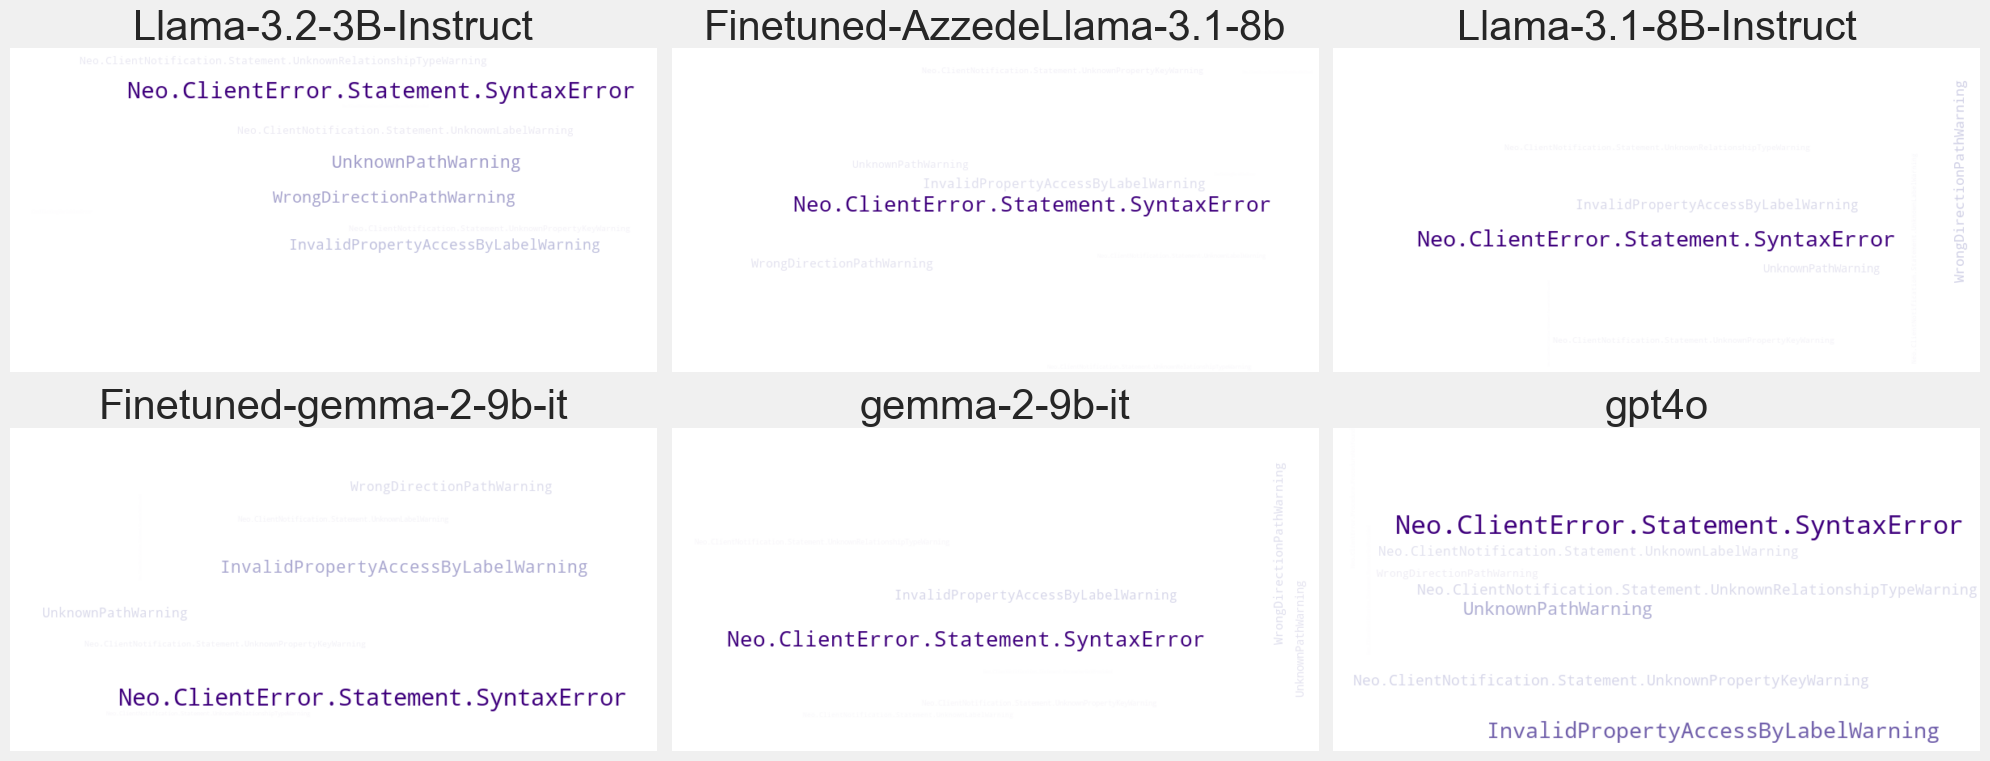

In [12]:
from wordcloud import WordCloud, STOPWORDS

models = list(extended_dfs_dict.keys())
n_models = len(models)

ncols = 3
nrows = int(np.ceil(n_models / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(20, 8))
axes_flat = axes.flatten()
fig.patch.set_facecolor('#f0f0f0')

for idx, model_name in enumerate(models):
    ax = axes_flat[idx]
    df = extended_dfs_dict[model_name]

    # Build your frequency dict of error codes
    error_counts = pd.Series([err for sublist in  df.flattened_cypher_errors_history for err in sublist]).value_counts()
    freqs = error_counts.to_dict()

    # Normalize frequencies for color mapping
    freq_values = np.array(list(freqs.values()))
    min_freq, max_freq = freq_values.min(), freq_values.max()
    freq_norm_dict = {word: (freq - min_freq) / (max_freq - min_freq + 1e-9) for word, freq in freqs.items()}

    # Choose a matplotlib colormap (e.g., Reds reversed so highest freq = darkest red)
    cmap = plt.colormaps.get_cmap('Purples')

    def color_func(word, font_size, position, orientation, random_state=None, **kwargs):
        norm_val = freq_norm_dict.get(word, 0)
        r, g, b, a = cmap(norm_val)
        return f"rgb({int(r*255)}, {int(g*255)}, {int(b*255)})"

    # Generate WordCloud with custom color_func
    wc = WordCloud(
        width=800,
        height=400,
        background_color='white',
        contour_color='steelblue',
        color_func=color_func
    ).generate_from_frequencies(freqs)

    # Draw onto the ax
    ax.imshow(wc.to_array(), interpolation='bilinear')
    ax.set_axis_off()
    ax.set_title(models_mapping[model_name], fontsize=30)

# Turn off any remaining empty subplots
for ax in axes_flat[n_models:]:
    ax.axis('off')

plt.tight_layout()
plt.show()


## 🗂️ Treemap Visualization per Model

The treemap below provides a visual summary of Cypher error types encountered for each model.  
- **Each colored rectangle** represents a specific error type, sized by its frequency for that model.
- **Top 20 errors** are shown individually; all others are grouped as "Other".
- This layout makes it easy to spot which error types are most common and compare error profiles across models.

Use this visualization to quickly identify error hotspots and model-specific patterns in Cypher query generation.

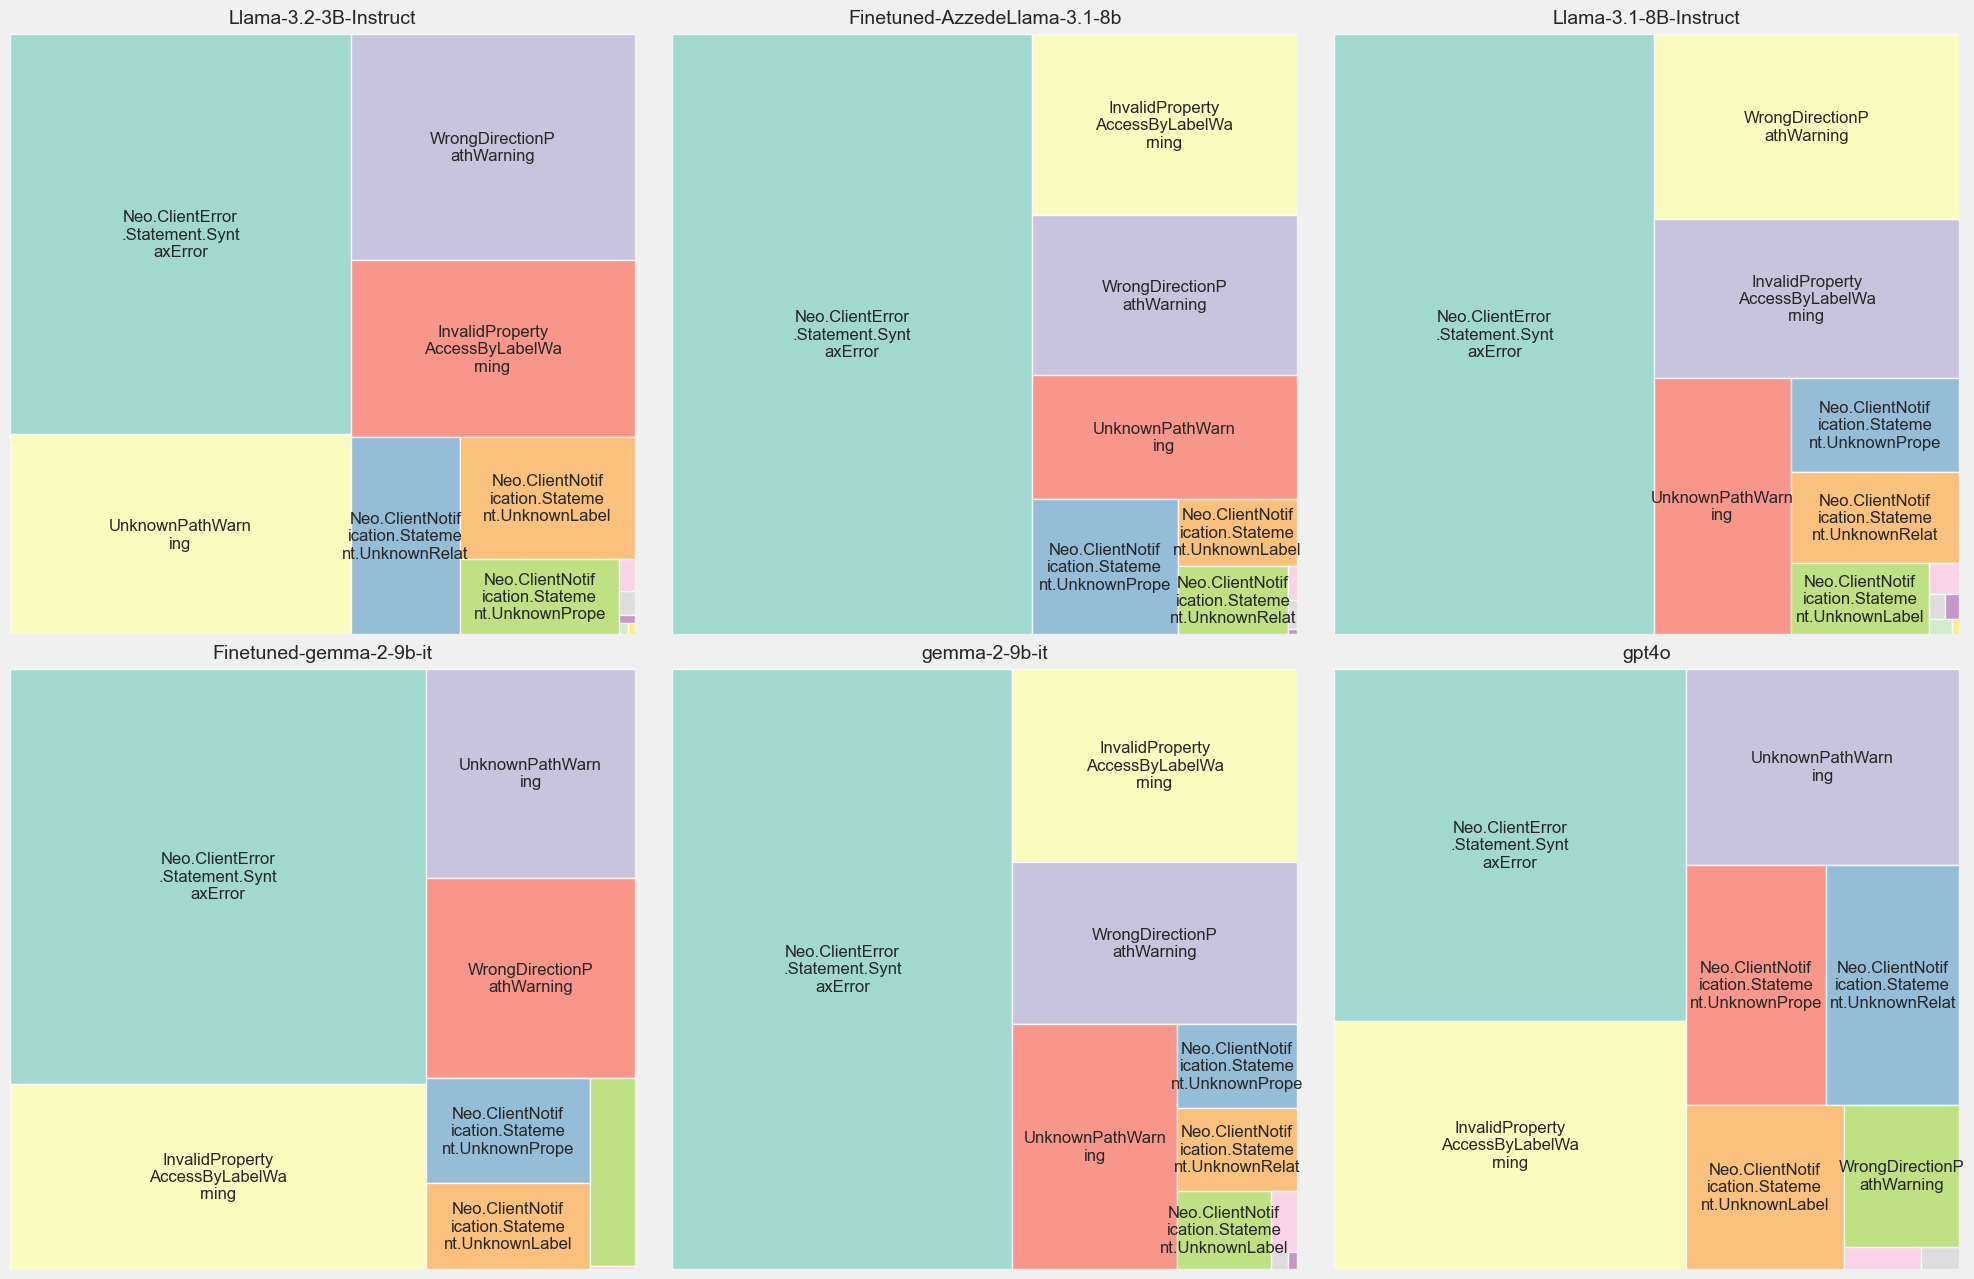

In [13]:
import squarify
import textwrap
from matplotlib.patches import Patch

models    = list(extended_dfs_dict.keys())
n_models  = len(models)
ncols     = 3
nrows     = int(np.ceil(n_models / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(20, 15))
axes_flat = axes.flatten()
fig.patch.set_facecolor('#f0f0f0')

def wrap_label(lbl, width=15):
    return "\n".join(textwrap.wrap(lbl, width=width))

def draw_wrapped_text(ax, x, y, width, height, text, fontsize=12, max_lines=3):
    # Wrap the text to fit max width (number of chars can be tuned)
    wrapped = textwrap.wrap(text, width=15)
    wrapped = wrapped[:max_lines]  # limit max lines
    wrapped_text = "\n".join(wrapped)
    # Draw centered text inside rectangle
    ax.text(
        x + width / 2,
        y + height / 2,
        wrapped_text,
        ha='center',
        va='center',
        fontsize=fontsize,
        wrap=True
    )

# Prepare combined error counts across all models for the legend
all_error_counts = pd.Series(dtype=int)
for model_name in models:
    df = extended_dfs_dict[model_name]
    error_counts = pd.Series([err for sub in  df.flattened_cypher_errors_history for err in sub]).value_counts()
    all_error_counts = all_error_counts.add(error_counts, fill_value=0)

# Top N + Other for the combined legend
N = 20
common = all_error_counts.nlargest(N)
labels = common.index.tolist()
sizes = common.values.tolist()
other = all_error_counts.sum() - sum(sizes)
if other > 0:
    labels.append("Other")
    sizes.append(other)

# Colors and wrapped labels for legend
cmap = plt.get_cmap('Set3')
colors = [cmap(i) for i in range(len(sizes))]
legend_labels = [wrap_label(lbl) for lbl in labels]

MIN_SIZE = 10  # minimum width and height to show text

for idx, model_name in enumerate(models):
    ax = axes_flat[idx]
    df = extended_dfs_dict[model_name]

    # Build frequency dict for this model
    error_counts = pd.Series([err for sub in  df.flattened_cypher_errors_history for err in sub]).value_counts()

    # Top N + Other
    common_model = error_counts.nlargest(N)
    labels_model = common_model.index.tolist()
    sizes_model  = common_model.values.tolist()
    other_model = error_counts.sum() - sum(sizes_model)
    if other_model > 0:
        labels_model.append("Other")
        sizes_model.append(other_model)

    # Normalize sizes to fit into 100x100 area
    norm_sizes = squarify.normalize_sizes(sizes_model, 100, 100)
    rects = squarify.squarify(norm_sizes, 0, 0, 100, 100)

    # Clear axis and draw treemap manually with wrapped text
    ax.clear()
    ax.axis('off')
    ax.set_title(models_mapping.get(model_name, model_name), fontsize=14, pad=8)

    for i, rect in enumerate(rects):
        x, y, dx, dy = rect['x'], rect['y'], rect['dx'], rect['dy']
        color = colors[i] if i < len(colors) else (0.8, 0.8, 0.8)  # fallback color

        ax.add_patch(plt.Rectangle((x, y), dx, dy, facecolor=color, edgecolor='white', linewidth=1, alpha=0.8))

        # Show text only if tile is big enough
        if dx > MIN_SIZE and dy > MIN_SIZE:
            draw_wrapped_text(ax, x, y, dx, dy, labels_model[i])

    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.invert_yaxis()

# Turn off any extra axes
for ax in axes_flat[n_models:]:
    ax.axis('off')

plt.tight_layout()
plt.subplots_adjust(bottom=0.15)  # make room for legend
plt.show()


# ➕ Additonal plots on Average of Persisten/New Errors per model

C:\Users\ioann\AppData\Local\Temp\ipykernel_30936\3477812946.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ci_sub['ci95_hi'] = ci_sub[mean_col] + 1.96 * ci_sub[sem_col]
C:\Users\ioann\AppData\Local\Temp\ipykernel_30936\3477812946.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ci_sub['ci95_lo'] = ci_sub[mean_col] - 1.96 * ci_sub[sem_col]
C:\Users\ioann\AppData\Local\Temp\ipykernel_30936\3477812946.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.


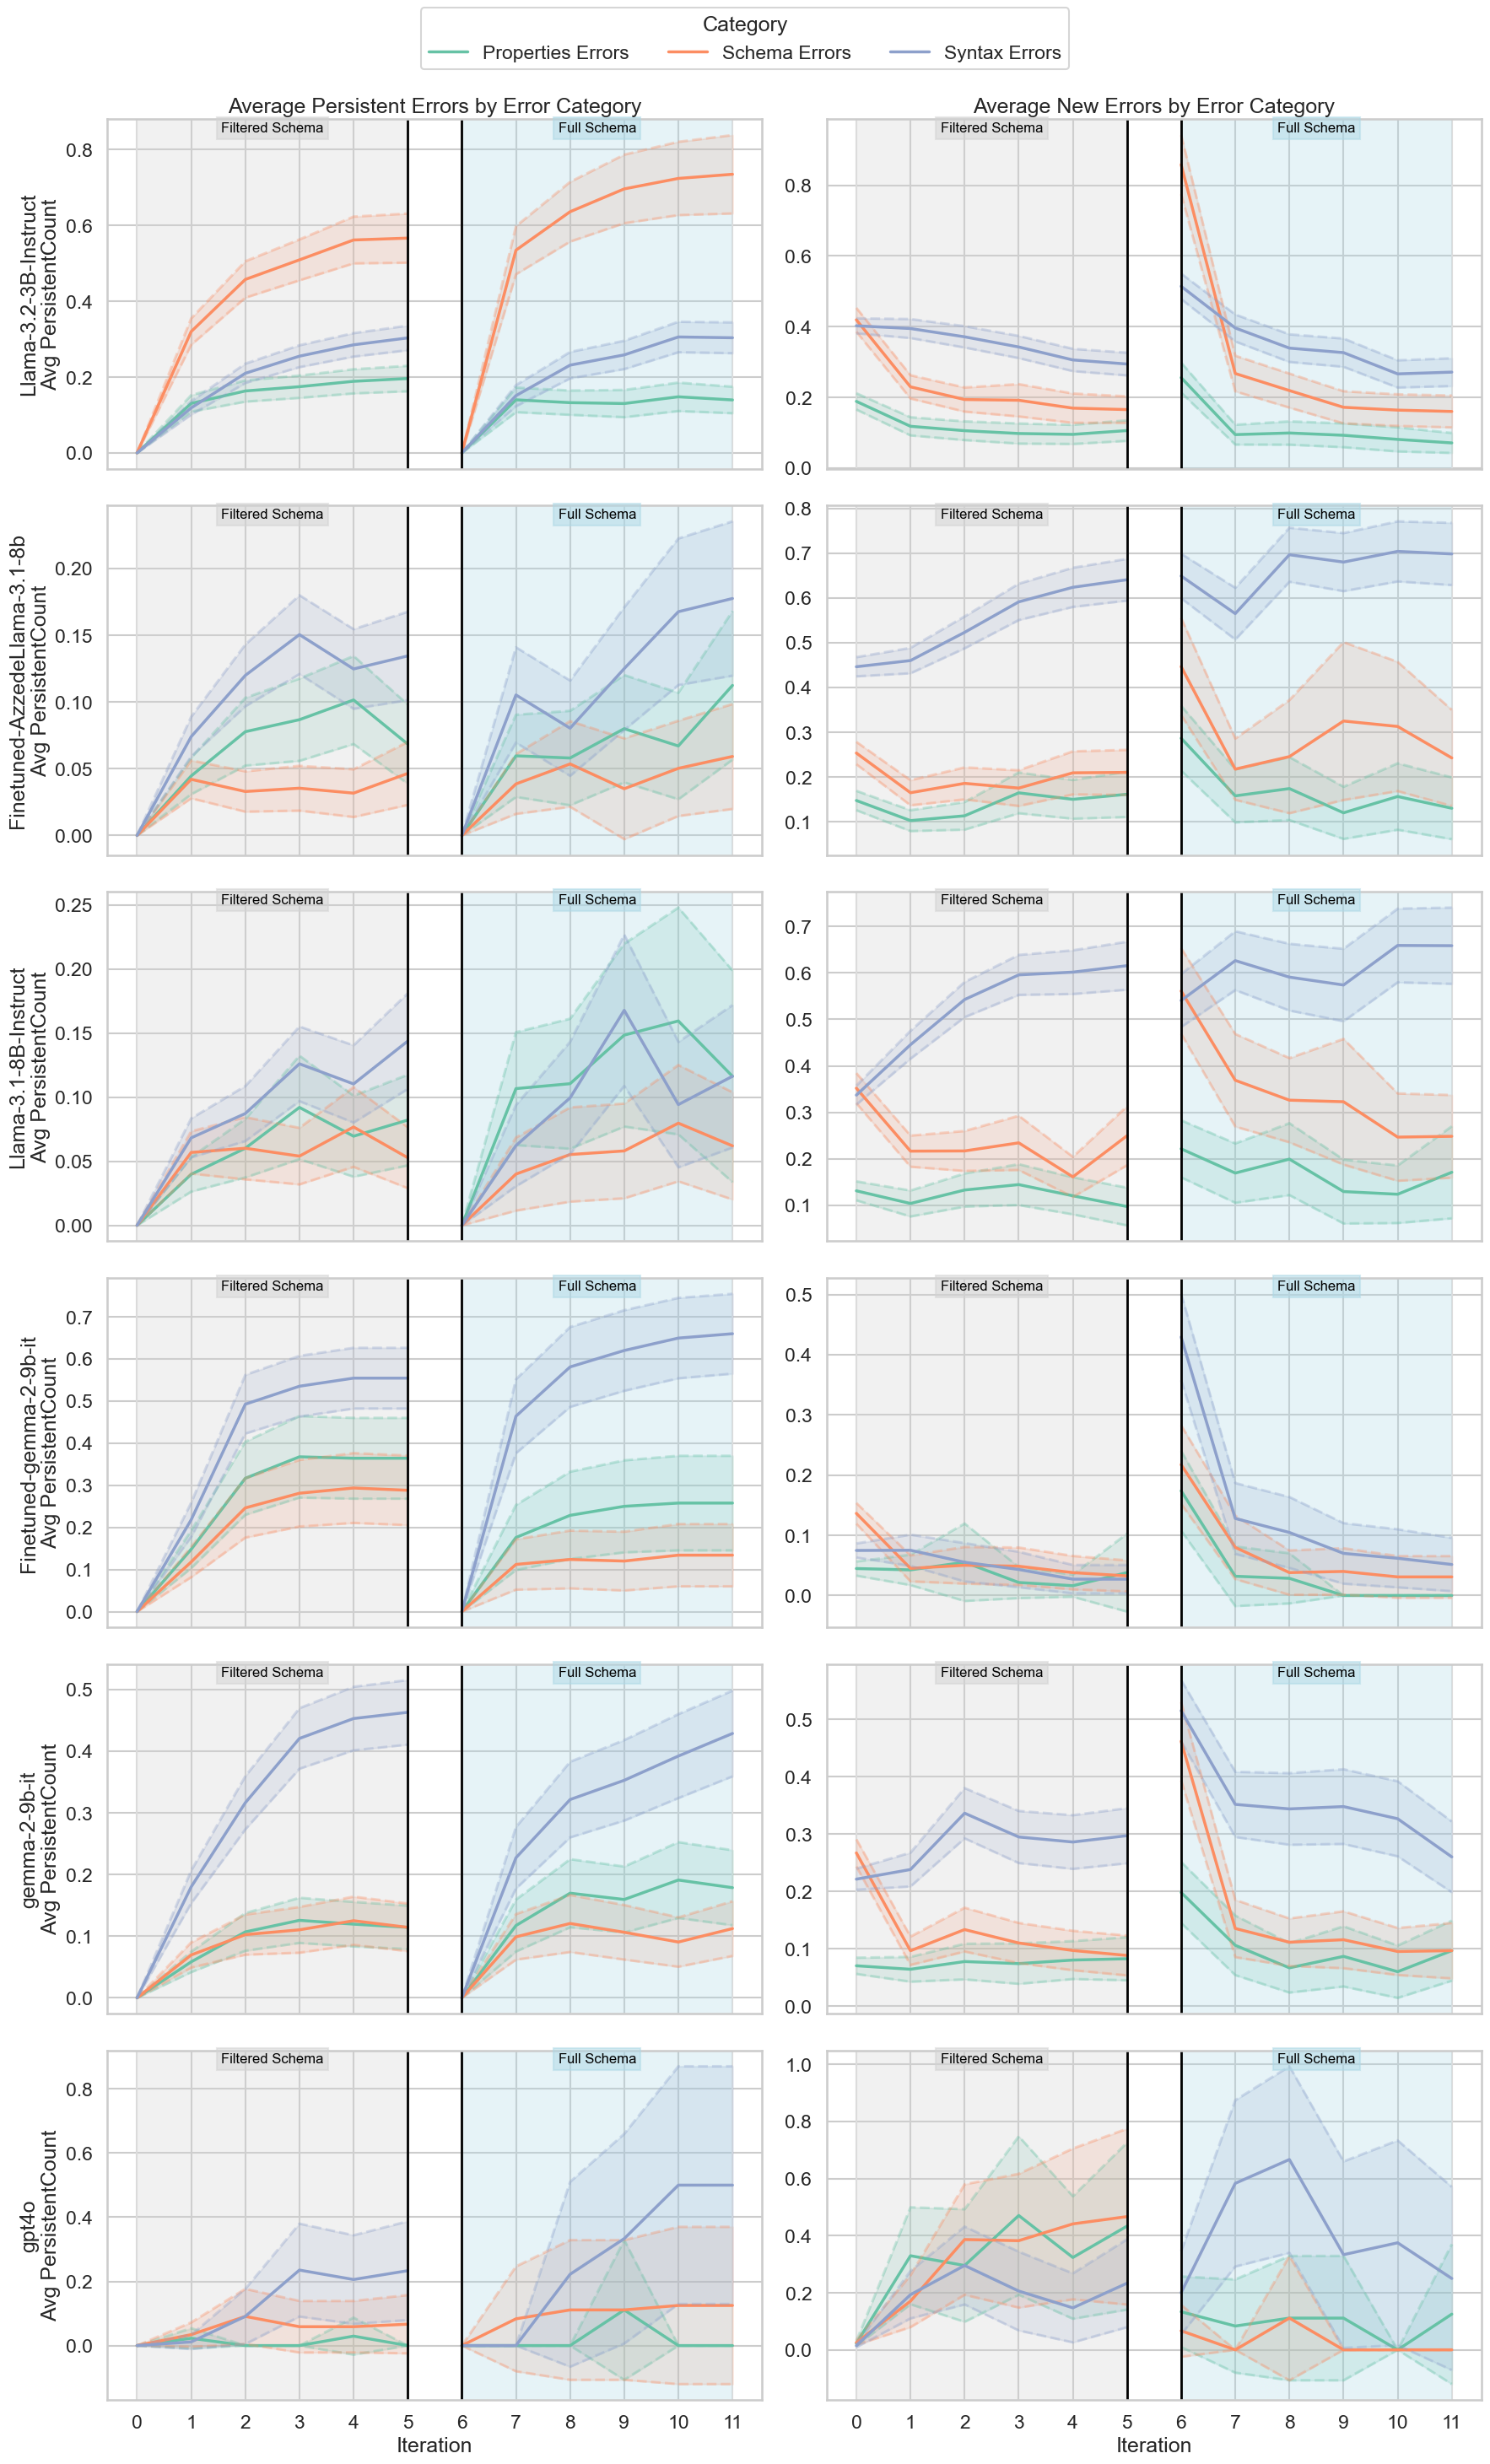

In [14]:
sns.set_style('whitegrid')
sns.set_context('talk')

metrics = ['PersistentCount', 'NewCount']
categories = errors_df['Category'].unique()
models = errors_df['Model'].unique()

metrics_map = {
    'PersistentCount': 'Persistent Errors',   
    'NewCount': 'New Errors'
}

palette = sns.color_palette("Set2", n_colors=len(categories))

fig, axes = plt.subplots(nrows=len(models), ncols=len(metrics), figsize=(18, 5 * len(models)), sharex=True)

for row_idx, model_name in enumerate(models):
    df = errors_df[errors_df['Model'] == model_name].copy()

    ci_df = (
        df
        .groupby(['Iteration', 'Category'])[metrics]
        .agg(['mean', sem])
        .reset_index()
    )
    ci_df.columns = ['Iteration', 'Category'] + [f'{metric}_{stat}' for metric, stat in ci_df.columns[2:]]

    for col_idx, metric in enumerate(metrics):
        ax = axes[row_idx, col_idx] if len(models) > 1 else axes[col_idx]

        avg_df = (
            df
            .groupby(['Iteration', 'Category'])[metric]
            .mean()
            .reset_index()
        )

        pivot = avg_df.pivot(index='Iteration', columns='Category', values=metric)

        pivot_first = pivot[pivot.index <= 5]
        pivot_second = pivot[pivot.index >= 6]

        for color, category in zip(palette, pivot.columns):
            # Plot mean line segments separately to create gap
            ax.plot(pivot_first.index, pivot_first[category], label=category, color=color, linewidth=2.5)
            ax.plot(pivot_second.index, pivot_second[category], color=color, linewidth=2.5)

            # Label at the end of second segment
            if not pivot_second.empty:
                x_end = pivot_second.index[-1]
                y_end = pivot_second[category].iloc[-1]
            else:
                x_end = pivot_first.index[-1]
                y_end = pivot_first[category].iloc[-1]

            # ax.text(x_end + 0.1, y_end, category, color=color, fontsize=10, va='center')

            # Plot CI intervals in two parts to avoid connecting over gap
            ci_sub = ci_df[ci_df['Category'] == category]

            mean_col = f'{metric}_mean'
            sem_col = f'{metric}_sem'
            ci_sub['ci95_hi'] = ci_sub[mean_col] + 1.96 * ci_sub[sem_col]
            ci_sub['ci95_lo'] = ci_sub[mean_col] - 1.96 * ci_sub[sem_col]

            ci_sub = ci_sub.sort_values('Iteration')

            # Split into two parts to create gap
            ci_first = ci_sub[ci_sub['Iteration'] <= 5]
            ci_second = ci_sub[ci_sub['Iteration'] >= 6]

            # Plot first segment CI
            ax.fill_between(ci_first['Iteration'], ci_first['ci95_lo'], ci_first['ci95_hi'], color=color, alpha=0.2)
            ax.plot(ci_first['Iteration'], ci_first['ci95_hi'], linestyle='--', alpha=0.3, color=color)
            ax.plot(ci_first['Iteration'], ci_first['ci95_lo'], linestyle='--', alpha=0.3, color=color)

            # Plot second segment CI
            ax.fill_between(ci_second['Iteration'], ci_second['ci95_lo'], ci_second['ci95_hi'], color=color, alpha=0.2)
            ax.plot(ci_second['Iteration'], ci_second['ci95_hi'], linestyle='--', alpha=0.3, color=color)
            ax.plot(ci_second['Iteration'], ci_second['ci95_lo'], linestyle='--', alpha=0.3, color=color)

        if row_idx == 0:
            ax.set_title(f'Average {metrics_map[metric]} by Error Category')
        if col_idx == 0:
            ax.set_ylabel(f'{model_name}\nAvg {metric}')
        if row_idx == len(models) - 1:
            ax.set_xlabel('Iteration')

        ax.axvline(x=5, color='black', linestyle='-', linewidth=2)
        ax.axvline(x=6, color='black', linestyle='-', linewidth=2)

        max_x = avg_df['Iteration'].max()

        ax.axvspan(0, 5, ymin=0, ymax=1, facecolor='lightgray', alpha=0.3)
        ax.axvspan(6, max_x, ymin=0, ymax=1, facecolor='lightblue', alpha=0.3)

        ymin, ymax = ax.get_ylim()
        y_center = ymax - (ymax - ymin) * 0.025 

        ax.text(2.5, y_center, 'Filtered Schema', fontsize=12, color='black',
                ha='center', va='center', bbox=dict(facecolor='lightgray', alpha=0.5, edgecolor='lightgray'))

        ax.text(8.5, y_center, 'Full Schema', fontsize=12, color='black',
                ha='center', va='center', bbox=dict(facecolor='lightblue', alpha=0.5, edgecolor='lightblue'))

        ax.grid(True)
        ax.set_xticks(np.arange(0, 10 + 2, 1))

handles, labels = axes[0,0].get_legend_handles_labels() if len(models) > 1 else axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title='Category', loc='upper center', ncol=len(labels), bbox_to_anchor=(0.5, 0.98))

fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


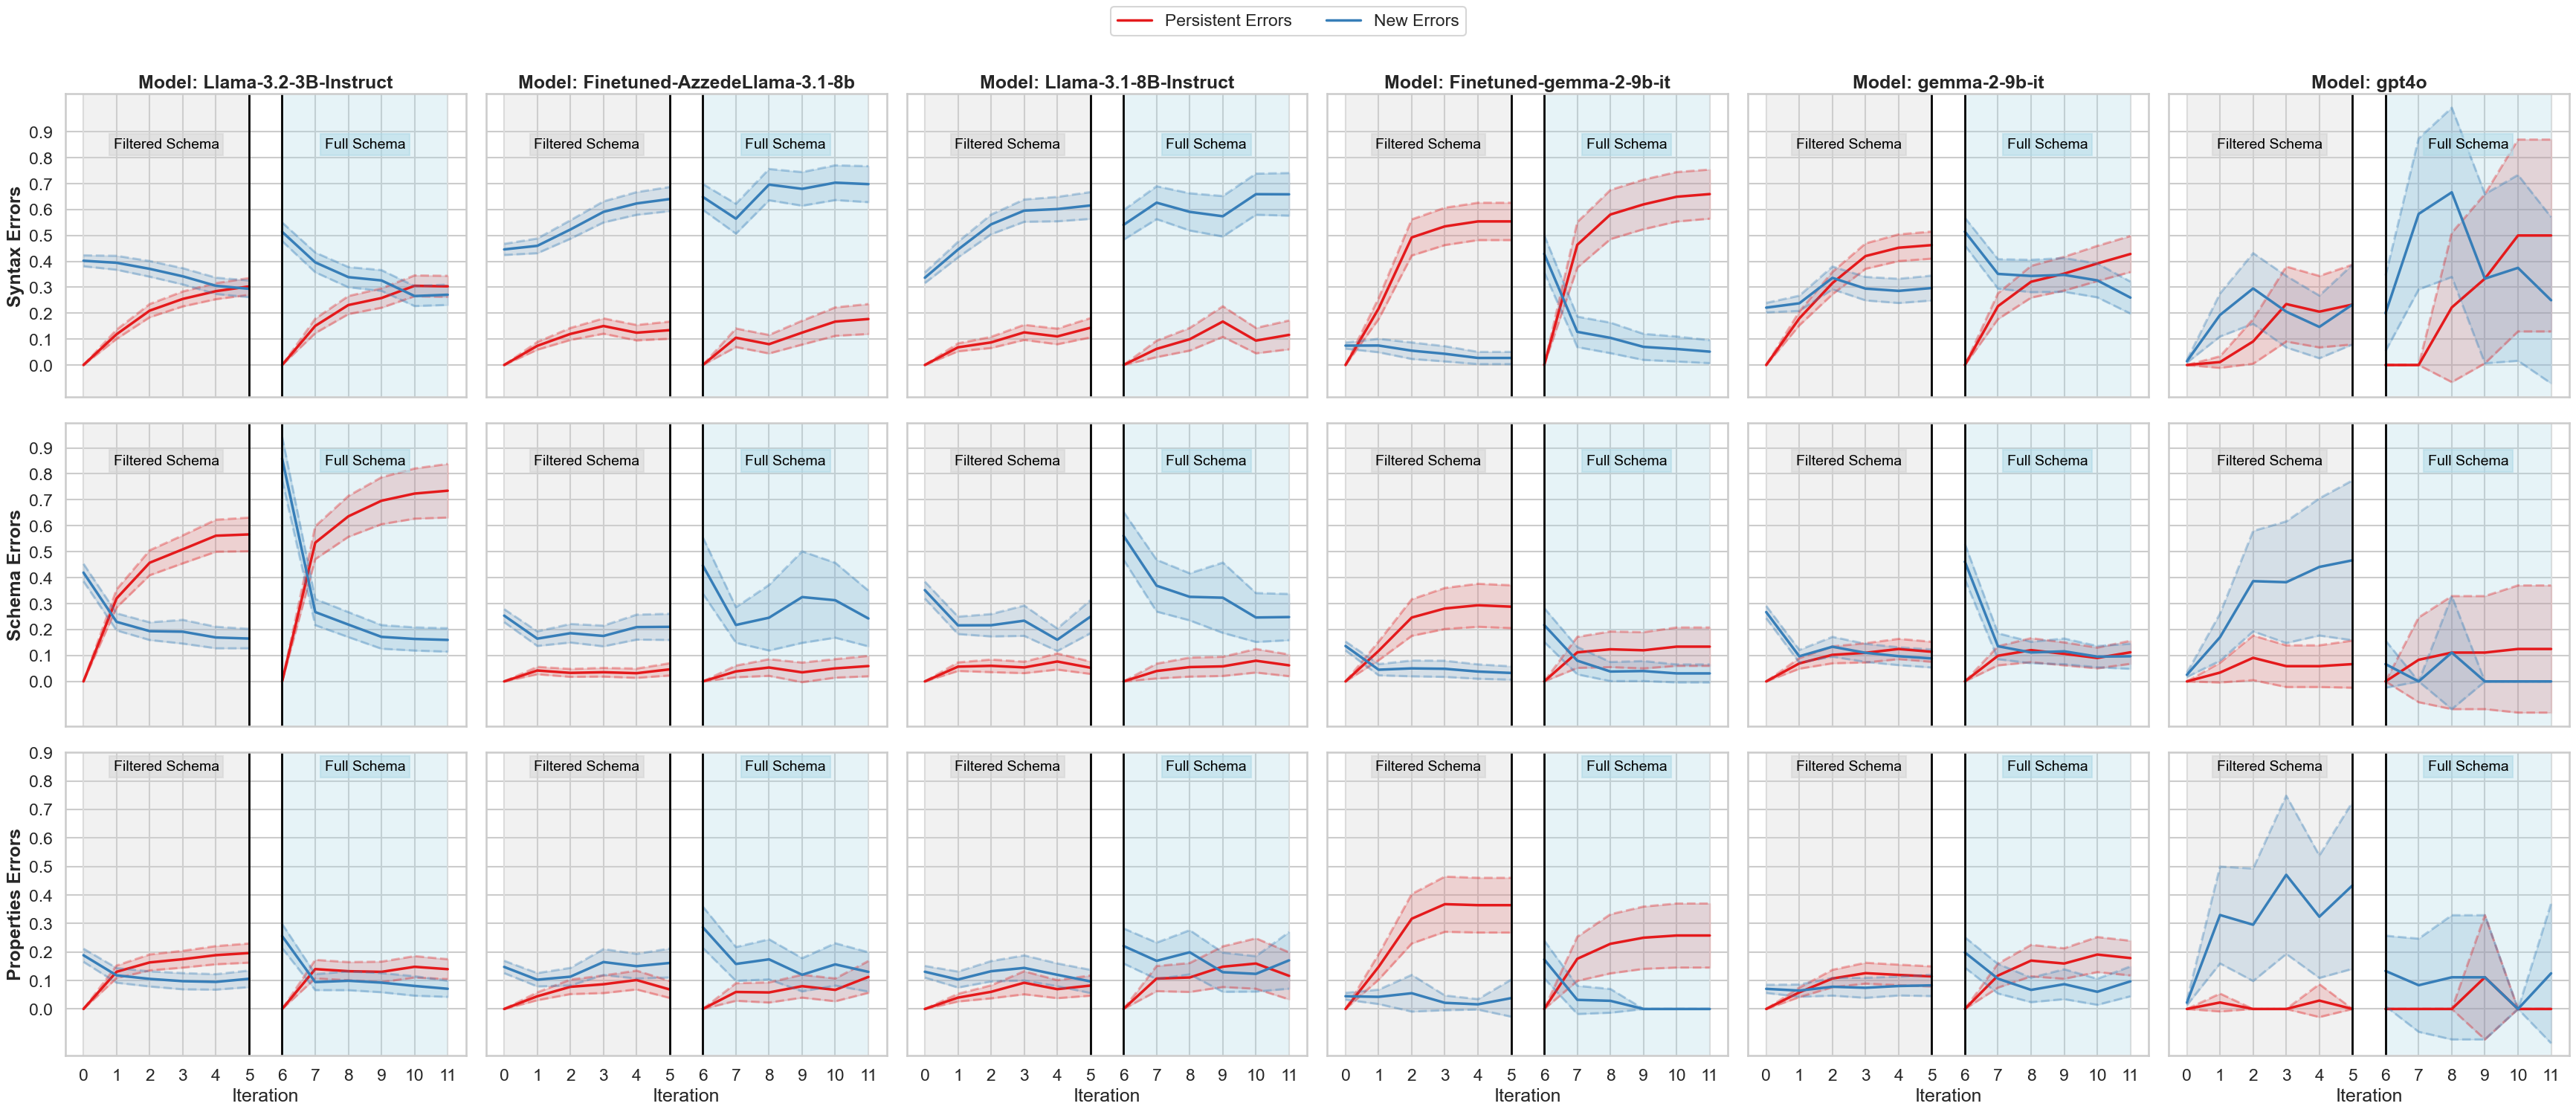

In [15]:
sns.set_style('whitegrid')
sns.set_context('talk')

metrics = ['PersistentCount', 'NewCount']
metrics_map = {
    'PersistentCount': 'Persistent Errors',   
    'NewCount': 'New Errors'
}

categories = errors_df['Category'].unique()
models = errors_df['Model'].unique()

palette = sns.color_palette("Set1", n_colors=len(metrics))  # Color per metric

fig, axes = plt.subplots(nrows=len(categories), ncols=len(models), figsize=(35,15), sharex=True, sharey='row')

for row_idx, category in enumerate(categories):
    for col_idx, model_name in enumerate(models):
        if len(categories) > 1 and len(models) > 1:
            ax = axes[row_idx, col_idx]
        elif len(categories) == 1 and len(models) > 1:
            ax = axes[col_idx]
        else:
            ax = axes[row_idx]

        df = errors_df[(errors_df['Model'] == model_name) & (errors_df['Category'] == category)].copy()

        # Compute mean and sem for each metric by iteration
        agg_df = (
            df.groupby('Iteration')[metrics]
            .agg(['mean', sem])
            .reset_index()
        )
        # Flatten multi-index columns
        agg_df.columns = ['Iteration'] + [f'{m}_{stat}' for m in metrics for stat in ['mean', 'sem']]

        pivot_first = agg_df[agg_df['Iteration'] <= 5]
        pivot_second = agg_df[agg_df['Iteration'] >= 6]

        for metric_idx, metric in enumerate(metrics):
            color = palette[metric_idx]

            # Plot mean lines for first segment
            ax.plot(pivot_first['Iteration'], pivot_first[f'{metric}_mean'], label=metrics_map[metric], color=color, linewidth=2.5)
            # Plot mean lines for second segment
            ax.plot(pivot_second['Iteration'], pivot_second[f'{metric}_mean'], color=color, linewidth=2.5)

            # Plot confidence intervals for first segment
            ci_upper_first = pivot_first[f'{metric}_mean'] + 1.96 * pivot_first[f'{metric}_sem']
            ci_lower_first = pivot_first[f'{metric}_mean'] - 1.96 * pivot_first[f'{metric}_sem']
            ax.fill_between(pivot_first['Iteration'], ci_lower_first, ci_upper_first, color=color, alpha=0.2)
            ax.plot(pivot_first['Iteration'], ci_upper_first, linestyle='--', color=color, alpha=0.3)
            ax.plot(pivot_first['Iteration'], ci_lower_first, linestyle='--', color=color, alpha=0.3)

            # Plot confidence intervals for second segment
            ci_upper_second = pivot_second[f'{metric}_mean'] + 1.96 * pivot_second[f'{metric}_sem']
            ci_lower_second = pivot_second[f'{metric}_mean'] - 1.96 * pivot_second[f'{metric}_sem']
            ax.fill_between(pivot_second['Iteration'], ci_lower_second, ci_upper_second, color=color, alpha=0.2)
            ax.plot(pivot_second['Iteration'], ci_upper_second, linestyle='--', color=color, alpha=0.3)
            ax.plot(pivot_second['Iteration'], ci_lower_second, linestyle='--', color=color, alpha=0.3)

            # Add label text at the end of second segment
            if not pivot_second.empty:
                x_end = pivot_second['Iteration'].iloc[-1]
                y_end = pivot_second[f'{metric}_mean'].iloc[-1]
            else:
                x_end = pivot_first['Iteration'].iloc[-1]
                y_end = pivot_first[f'{metric}_mean'].iloc[-1]

            # ax.text(x_end + 0.1, y_end, metrics_map[metric], color=color, fontsize=14, va='center')

        if col_idx == 0:
            ax.set_ylabel(category, fontsize=18, fontweight='bold')
        if row_idx == len(categories) - 1:
            ax.set_xlabel('Iteration')
        if row_idx == 0:
            ax.set_title(f'Model: {model_name}', fontsize=18, fontweight='bold')

        ax.axvline(x=5, color='black', linestyle='-', linewidth=2)
        ax.axvline(x=6, color='black', linestyle='-', linewidth=2)

        max_x = agg_df['Iteration'].max()

        ax.axvspan(0, 5, ymin=0, ymax=1, facecolor='lightgray', alpha=0.3)
        ax.axvspan(6, max_x, ymin=0, ymax=1, facecolor='lightblue', alpha=0.3)

        ymin, ymax = ax.get_ylim()
        y_center = ymax - (ymax - ymin) * 0.025

        ax.text(2.5, 0.85, 'Filtered Schema', fontsize=14, color='black',
                ha='center', va='center', bbox=dict(facecolor='lightgray', alpha=0.5, edgecolor='lightgray'))

        ax.text(8.5, 0.85, 'Full Schema', fontsize=14, color='black',
                ha='center', va='center', bbox=dict(facecolor='lightblue', alpha=0.5, edgecolor='lightblue'))

        ax.grid(True)
        ax.set_xticks(np.arange(0, 12, 1))
        ax.set_yticks(np.arange(0, 1, 0.1))

# Adjust layout
fig.tight_layout(rect=[0, 0, 1, 0.96])
handles, labels = axes[0,0].get_legend_handles_labels() if len(models) > 1 else axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title='', loc='upper center', ncol=len(labels), bbox_to_anchor=(0.5, 1.01))
# fig.suptitle('Error Analysis by Category and Model', fontsize=20, fontweight='bold', y=1.02)

plt.show()


# 📋 Additional Statistical Tests

In [16]:
import statsmodels.formula.api as smf
from scipy.stats import ttest_rel, wilcoxon, friedmanchisquare
import numpy as np
import pandas as pd
import scipy.stats as stats
import pymannkendall as mk
from statsmodels.stats.diagnostic import acorr_ljungbox

## Trend Analysis across all models

In [17]:
df = errors_df.copy()
results = []

groups = df['Group'].unique()
metrics = ['NewCount', 'DisappearedCount', 'PersistentCount']

def run_mk_with_autocorrelation(series):
    if len(series) < 3:
        return None
    lb_test = acorr_ljungbox(series, lags=[len(series)-1], return_df=True)
    if lb_test["lb_pvalue"].iloc[-1] > 0.05:
        return mk.original_test(series)
    else:
        return mk.pre_whitening_modification_test(series)

for group_label in groups:
    phase_df = df[df['Group'] == group_label].copy()
    for category in phase_df['Category'].unique():
        sub = phase_df[
            (phase_df['Category'] == category)
        ].sort_values(['RunID', 'Iteration'])

        if sub.empty:
            continue

        agg = sub.groupby('Iteration').agg({m: 'mean' for m in metrics}).reset_index()

        mk_results = {m: run_mk_with_autocorrelation(agg[m]) for m in metrics}
        spearman_results = {m: stats.spearmanr(agg['Iteration'], agg[m]) if len(agg) >= 3 else None for m in metrics}

        try:
            w_stat, w_p = stats.wilcoxon(agg['NewCount'], agg['DisappearedCount'])
        except ValueError:
            w_stat, w_p = np.nan, np.nan

        print(f"\n📌 Phase: Iteration {group_label} | Category: {category}")
        for m in metrics:
            mk_res = mk_results[m]
            sp_res = spearman_results[m]
            if mk_res:
                trend = "increasing" if mk_res.slope > 0 else "decreasing"
                sig = "significant" if mk_res.p < 0.05 else "not significant"
                print(f" • {m}: {sig} {trend} trend (slope={mk_res.slope:.3f}, p={mk_res.p:.4f}), trend = {mk_res.trend}")
            else:
                print(f" • {m}: Insufficient data for Mann-Kendall test.")

            if sp_res:
                direction = "positive" if sp_res.correlation > 0 else "negative"
                sig = "significant" if sp_res.pvalue < 0.05 else "not significant"
                print(f"   Spearman: {sig} {direction} (rho={sp_res.correlation:.3f}, p={sp_res.pvalue:.4f})")
            else:
                print(f"   Spearman: Insufficient data")

        results.append({
            'Group': group_label,
            'Category': category,
            **{f"mk_{m}_slope": mk_results[m].slope if mk_results[m] else np.nan for m in metrics},
            **{f"mk_{m}_p": mk_results[m].p if mk_results[m] else np.nan for m in metrics},
            **{f"spearman_{m}_rho": spearman_results[m].correlation if spearman_results[m] else np.nan for m in metrics},
            **{f"spearman_{m}_p": spearman_results[m].pvalue if spearman_results[m] else np.nan for m in metrics},
        })

results_df = pd.DataFrame(results)



📌 Phase: Iteration KG Valid Queries (Filtered Schema) | Category: Syntax Errors
 • NewCount: not significant increasing trend (slope=0.009, p=1.0000), trend = no trend
   Spearman: not significant negative (rho=-0.029, p=0.9572)
 • DisappearedCount: significant increasing trend (slope=0.075, p=0.0085), trend = increasing
   Spearman: significant positive (rho=1.000, p=0.0000)
 • PersistentCount: not significant decreasing trend (slope=-0.005, p=0.8483), trend = no trend
   Spearman: not significant negative (rho=-0.116, p=0.8268)

📌 Phase: Iteration KG Valid Queries (Filtered Schema) | Category: Schema Errors
 • NewCount: significant decreasing trend (slope=-0.023, p=0.0242), trend = decreasing
   Spearman: significant negative (rho=-0.943, p=0.0048)
 • DisappearedCount: not significant decreasing trend (slope=-0.019, p=0.7071), trend = no trend
   Spearman: not significant negative (rho=-0.086, p=0.8717)
 • PersistentCount: not significant decreasing trend (slope=-0.004, p=0.8483), t

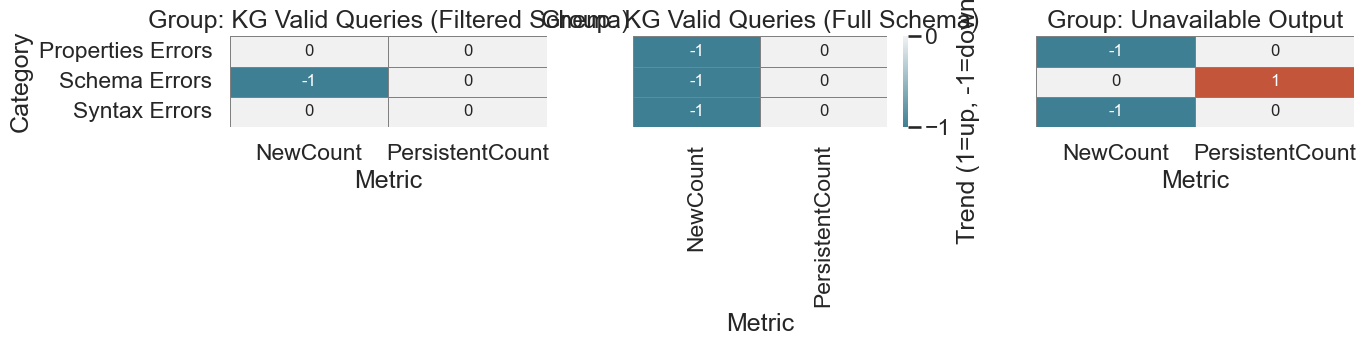

In [18]:
metrics = ['NewCount', 'PersistentCount']

# Prepare data as before
records = []
for _, row in results_df.iterrows():
    for m in metrics:
        slope = row[f'mk_{m}_slope']
        pval = row[f'mk_{m}_p']
        if pd.isna(slope) or pd.isna(pval):
            continue
        trend = 0
        if pval < 0.05:
            trend = 1 if slope > 0 else -1
        records.append({
            'Category': row['Category'],
            'Group': row['Group'],
            'Metric': m,
            'Trend': trend,  # 1=up, -1=down, 0=ns
            'Slope': slope,
            'p_value': pval
        })

plot_df = pd.DataFrame(records)

groups = df.Group.unique()

fig, axes = plt.subplots(1, 3, figsize=(14, max(4, len(plot_df['Category'].unique())*0.6)), sharey=True)

for i, group_label in enumerate(groups):
    subset = plot_df[(plot_df['Group'] == group_label)]
    if subset.empty:
        axes[i].set_visible(False)
        continue
    
    heat_data = subset.pivot(index='Category', columns='Metric', values='Trend').fillna(0)
    
    cmap = sns.diverging_palette(220, 20, as_cmap=True)
    
    sns.heatmap(
        heat_data,
        cmap=cmap,
        center=0,
        cbar=i==1,  # show colorbar only on right plot
        cbar_kws={'label': 'Trend (1=up, -1=down, 0=ns)'},
        linewidths=0.5,
        linecolor='gray',
        annot=True,
        fmt='d',
        annot_kws={"size": 12},
        square=False,
        ax=axes[i]
    )
    axes[i].set_title(f'Group: {group_label}')
    axes[i].set_xlabel('Metric')
    if i == 0:
        axes[i].set_ylabel('Category')
    else:
        axes[i].set_ylabel('')

# fig.suptitle(f'Significant Mann-Kendall Trends for Model: {model}', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


## Friedman + Nemenyi Test Summary

For each error category (e.g., "Syntax Errors", "Logic Errors"):

- **Friedman test:**
  - If p-value ≥ 0.05 → No significant difference between models.
  - If p-value < 0.05 → Models differ significantly.

- **Average ranks:**
  - Models ranked per run (1 = best).
  - Average rank across runs shows overall performance.
  - Lower average rank = better model.
  - Higher average rank = worse model.

- **Nemenyi post-hoc test (if Friedman significant):**
  - Identifies which pairs of models differ significantly.
  - Shows specifically which models outperform others.


In [19]:
import pandas as pd
from scipy.stats import friedmanchisquare
import scikit_posthocs as sp  # make sure you have scikit-posthocs installed

def run_friedman_nemenyi(df, value_col='NewCount'):
    """
    Run Friedman test + Nemenyi post-hoc analysis across models for each error category,
    and compute average ranks of models.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame with columns ['RunID', 'Model', 'Category', value_col]
    value_col : str
        The metric to compare, e.g., 'NewCount', 'DeltaCount', etc.

    Returns
    -------
    pd.DataFrame
        A summary DataFrame with Friedman stats, post-hoc p-value matrices, and average ranks per category.
    """
    results = []

    df = df.groupby(['RunID', 'Model', 'Category'])[value_col].mean().reset_index()

    for cat in df['Category'].unique():
        sub = df[df['Category'] == cat]

        # Pivot to shape: RunID x Model
        pivot = sub.pivot_table(index='RunID', columns='Model', values=value_col)

        # Drop runs with missing values
        pivot = pivot.dropna()

        # Need at least 2 models and 2 runs to run Friedman
        if pivot.shape[1] < 2 or pivot.shape[0] < 2:
            continue

        # Friedman test
        stat, p_val = friedmanchisquare(*[pivot[model].values for model in pivot.columns])

        # Compute average rank per model (lower rank = better)
        ranks = pivot.rank(axis=1, method='average')
        avg_ranks = ranks.mean().sort_values()

        # Nemenyi post-hoc test
        nemenyi_result = None
        if p_val < 0.05:
            nemenyi_result = sp.posthoc_nemenyi_friedman(pivot)

        results.append({
            'Category': cat,
            'friedman_stat': stat,
            'p_friedman': p_val,
            'p_posthoc_matrix': nemenyi_result,
            'avg_ranks': avg_ranks
        })

    return pd.DataFrame(results)

def extract_significant_pairs(p_matrix, alpha=0.05):
    sig_pairs = []
    if p_matrix is None:
        return sig_pairs
    models = p_matrix.columns
    for i, m1 in enumerate(models):
        for j, m2 in enumerate(models):
            if j <= i:
                continue
            if p_matrix.loc[m1, m2] < alpha:
                sig_pairs.append((m1, m2, p_matrix.loc[m1, m2]))
    return sig_pairs

In [20]:
print("\n→ Running Friedman + Nemenyi tests...")
fr_res = run_friedman_nemenyi(errors_df, value_col='NewCount')

for r in fr_res.itertuples():
    print(f"\n== {r.Category} ==")
    print(f"Friedman χ² stat: {r.friedman_stat:.4f}, p = {r.p_friedman:.4g}")

    print("\nAverage model ranks (lower = better):")
    for model, rank in r.avg_ranks.items():
        print(f"   {model}: {rank:.2f}")

    if r.p_friedman < 0.05:
        print("\n→ Significant differences between models:")
        sig_pairs = extract_significant_pairs(r.p_posthoc_matrix)
        for m1, m2, pval in sig_pairs:
            print(f"   {m1} vs {m2} → p = {pval:.4f}")
    else:
        print("→ No significant difference between models detected.")



→ Running Friedman + Nemenyi tests...

== Properties Errors ==
Friedman χ² stat: 607.1279, p = 5.831e-129

Average model ranks (lower = better):
   gpt4o: 3.24
   Finetuned-gemma-2-9b-it: 3.30
   gemma-2-9b-it: 3.38
   Llama-3.1-8B-Instruct: 3.61
   Finetuned-AzzedeLlama-3.1-8b: 3.69
   Llama-3.2-3B-Instruct: 3.79

→ Significant differences between models:
   Finetuned-AzzedeLlama-3.1-8b vs Finetuned-gemma-2-9b-it → p = 0.0000
   Finetuned-AzzedeLlama-3.1-8b vs gemma-2-9b-it → p = 0.0000
   Finetuned-AzzedeLlama-3.1-8b vs gpt4o → p = 0.0000
   Finetuned-gemma-2-9b-it vs Llama-3.1-8B-Instruct → p = 0.0000
   Finetuned-gemma-2-9b-it vs Llama-3.2-3B-Instruct → p = 0.0000
   Llama-3.1-8B-Instruct vs Llama-3.2-3B-Instruct → p = 0.0423
   Llama-3.1-8B-Instruct vs gemma-2-9b-it → p = 0.0012
   Llama-3.1-8B-Instruct vs gpt4o → p = 0.0000
   Llama-3.2-3B-Instruct vs gemma-2-9b-it → p = 0.0000
   Llama-3.2-3B-Instruct vs gpt4o → p = 0.0000

== Schema Errors ==
Friedman χ² stat: 887.0706, p = 1.

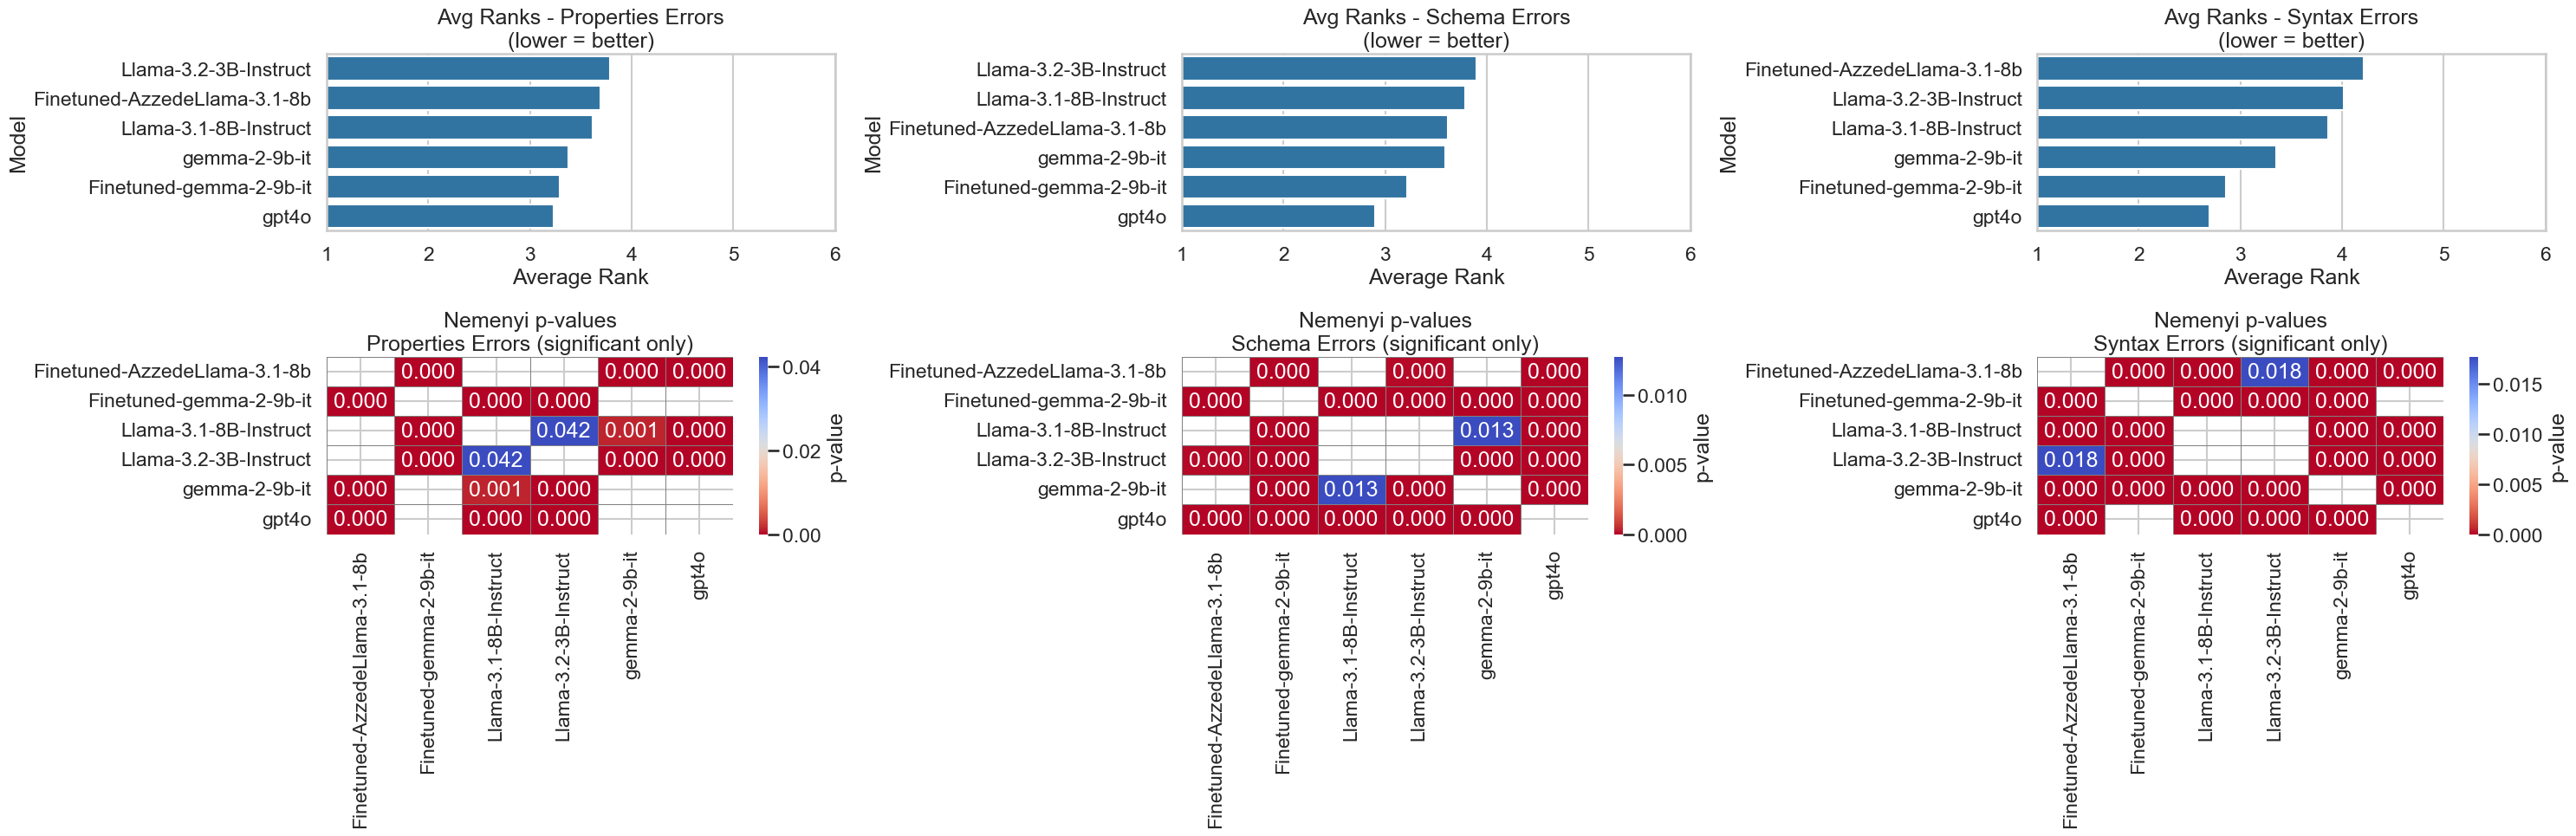

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

num_cats = len(fr_res)
if num_cats > 3:
    num_cats = 3  # restrict to 3 categories for layout

fig, axes = plt.subplots(2, num_cats, figsize=(30,10))

if num_cats == 1:
    axes = axes.reshape(2,1)  # make sure axes is 2D

# Row 1: Barplots of average ranks
for i, r in enumerate(fr_res.itertuples()):
    if i >= num_cats:
        break
    ranks = r.avg_ranks.sort_values()
    sns.barplot(x=ranks.values, y=ranks.index, ax=axes[0, i])
    axes[0, i].set_title(f"Avg Ranks - {r.Category}\n(lower = better)")
    axes[0, i].set_xlabel("Average Rank")
    axes[0, i].set_ylabel("Model")
    axes[0, i].set_xlim(1, len(ranks))
    axes[0, i].invert_yaxis()

# Row 2: Heatmaps of significant Nemenyi p-values
for i, r in enumerate(fr_res.itertuples()):
    if i >= num_cats:
        break
    ax = axes[1, i]

    if r.p_friedman < 0.05 and r.p_posthoc_matrix is not None:
        # Mask non-significant p-values >= 0.05
        pvals = r.p_posthoc_matrix.copy()
        mask = pvals >= 0.05
        sns.heatmap(
            pvals, annot=True, fmt=".3f", cmap='coolwarm_r',
            mask=mask, cbar_kws={'label': 'p-value'},
            ax=ax, linewidths=0.5, linecolor='gray'
        )
        ax.set_title(f"Nemenyi p-values\n{r.Category} (significant only)")
    else:
        ax.axis('off')
        ax.text(0.5, 0.5, "No significant differences", ha='center', va='center', fontsize=6)

plt.tight_layout()
plt.show()
